# Internet Advertisements: Big Data Hackathon

**Final integrated analysis notebook.** It documents data cleaning/selection/transformation, association mining, supervised classification, clustering, PySpark implementation status, plots, and reproducibility.

- **Dataset:** [UCI Internet Advertisements](https://archive.ics.uci.edu/dataset/51/internet%2Badvertisements)
- **Target:** `class` (`ad` / `nonad`)
- **Raw data:** the original UCI files are preserved in `data/raw/`; the cleaned copy is separate and keeps missing values.
- **Important limits:** the data-derived `origurl → ancurl → url` pattern analysis uses an analyst-defined structural order, not event chronology. The source has no timestamps or sessions. Both PySpark workloads executed on `local[2]`; Spark was slower than the matched local implementations on this small dataset.

The handout requires a readable PDF and source files. The final LaTeX report is being prepared separately from the saved analysis outputs.

## Assignment scope and execution plan

The WhatsApp handout asks for preprocessing, at least ten distinct plots with inferences, Apriori association mining (including the sequential-pattern wording), Decision Tree and DBSCAN analysis, CHARM closed itemsets/rules, two PySpark techniques, a local/Spark performance comparison, and a final PDF with source files.

This notebook reports executed values. A data-derived structural pattern analysis orders URL-named feature families, but the dataset has no timestamps, sessions, or natural event order; temporal sequence mining therefore remains unsupported. The synthetic GSP illustration is also separate. Both PySpark workloads executed in local mode and were slower than the matched local baselines.

The analysis builds on the raw-data checkpoint, corrected target-separated association outputs, grouped train/test tree artifacts, DBSCAN sensitivity output, and completed matched local/PySpark measurements in `artifacts/`.

## 1. Setup and download

The next cell downloads the official UCI archive only when it is not already present, then extracts the three expected source files into `data/raw/`.


In [1]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

DATA_URL = "https://archive.ics.uci.edu/static/public/51/internet+advertisements.zip"
WORK_DIR = Path.cwd()
if (WORK_DIR / "bdHackathon").is_dir():
    WORK_DIR = WORK_DIR / "bdHackathon"
RAW_DIR = WORK_DIR / "data" / "raw"
ARCHIVE_PATH = RAW_DIR / "internet-advertisements.zip"
RAW_DIR.mkdir(parents=True, exist_ok=True)

if not ARCHIVE_PATH.exists():
    urlretrieve(DATA_URL, ARCHIVE_PATH)

expected_files = {"ad.data", "ad.names", "ad.DOCUMENTATION"}
with ZipFile(ARCHIVE_PATH) as archive:
    available_files = set(archive.namelist())
    missing_files = expected_files - available_files
    if missing_files:
        raise ValueError(f"Unexpected UCI archive; missing files: {sorted(missing_files)}")
    for filename in expected_files:
        destination = RAW_DIR / filename
        if not destination.exists():
            destination.write_bytes(archive.read(filename))

print(f"Raw files are in: {RAW_DIR.resolve()}")
print("Files:", sorted(p.name for p in RAW_DIR.iterdir() if p.is_file()))


Raw files are in: /home/arpit/7th Sem/bigData/bdHackathon/data/raw
Files: ['ad.DOCUMENTATION', 'ad.data', 'ad.names', 'internet-advertisements.zip']


## 2. Parse the source files

`ad.data` has no header row. The names file declares 1,558 input attributes; the final column in each data row is the class label. The source labels have trailing periods, which we trim during loading.


In [2]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

if str(WORK_DIR) not in sys.path:
    sys.path.insert(0, str(WORK_DIR))
from hackathon_utils import load_ads

data, feature_names, NUMERIC_FEATURES, BINARY_FEATURES = load_ads(RAW_DIR)
TARGET = "class"

print(f"Loaded shape: {data.shape[0]:,} rows × {data.shape[1]:,} columns (target included)")
print("Geometry features:", NUMERIC_FEATURES)
print(f"Binary indicator features: {len(BINARY_FEATURES):,}")
print("Labels:", sorted(data[TARGET].dropna().unique().tolist()))
display(data[[*NUMERIC_FEATURES, *BINARY_FEATURES[:4], TARGET]].head())


Loaded shape: 3,279 rows × 1,559 columns (target included)
Geometry features: ['height', 'width', 'aratio']
Binary indicator features: 1,555
Labels: ['ad', 'nonad']


,height,width,aratio,local,url*images+buttons,url*likesbooks.com,url*www.slake.com,class
0,125.0,125.0,1.0000,1.0,0,0,0,ad
1,57.0,468.0,8.2105,1.0,0,0,0,ad
2,33.0,230.0,6.9696,1.0,0,0,0,ad
3,60.0,468.0,7.8000,1.0,0,0,0,ad
4,60.0,468.0,7.8000,1.0,0,0,0,ad


In [3]:
from importlib.metadata import PackageNotFoundError, version

required_packages = ["pandas", "numpy", "matplotlib", "ipython"]
package_versions = {}
for package in required_packages:
    try:
        package_versions[package] = version(package)
    except PackageNotFoundError:
        package_versions[package] = "not installed"
print("Python package versions:", package_versions)


Python package versions: {'pandas': '2.3.2', 'numpy': '1.26.4', 'matplotlib': '3.10.6', 'ipython': '8.37.0'}


## 3. First data-quality pass

Missing values mean **unknown**, not zero. The source documentation calls out missing geometry values, and the downloaded file also contains 15 missing values in the binary `local` field. Keep missing values visible during descriptive analysis. Later, use training-fold imputation for supervised models and an explicit imputation step before distance-based clustering. Repeated rows should be inspected before any removal because identical feature patterns may still represent separate examples.


In [4]:
class_counts = data[TARGET].value_counts(dropna=False).rename_axis(TARGET).to_frame("count")
class_counts["percent"] = (100 * class_counts["count"] / len(data)).round(2)

missing_by_column = data.isna().sum().sort_values(ascending=False)
missing_by_column = missing_by_column[missing_by_column > 0].rename("missing_count").to_frame()
missing_by_column["percent"] = (100 * missing_by_column["missing_count"] / len(data)).round(2)

feature_cardinality = data[feature_names].nunique(dropna=True)
constant_features = feature_cardinality[feature_cardinality <= 1]

print("Class balance in the downloaded file")
display(class_counts)
print(f"\nColumns containing missing values: {len(missing_by_column)}")
display(missing_by_column)
print(f"\nExact duplicate rows (including class): {data.duplicated().sum():,}")
print(f"Constant input features: {len(constant_features):,}")
print("\nGeometry-feature summary (missing values omitted):")
display(data[NUMERIC_FEATURES].describe().T)


Class balance in the downloaded file

Columns containing missing values: 4

Exact duplicate rows (including class): 856
Constant input features: 0

Geometry-feature summary (missing values omitted):


,count,percent
class,,
nonad,2820,86.0
ad,459,14.0


,missing_count,percent
aratio,910,27.75
height,903,27.54
width,901,27.48
local,15,0.46


,count,mean,std,min,25%,50%,75%,max
height,2376.0,64.021886,54.868604,1.0000,25.0000,51.000,85.2500,640.0
width,2378.0,155.344828,130.032350,1.0000,80.0000,110.000,184.0000,640.0
aratio,2369.0,3.911953,6.042986,0.0015,1.0357,2.102,5.3333,60.0


### Initial interpretation

The parsed archive contains 2,820 nonads and 459 ads, or about 86% and 14%. Compare class-aware metrics later; accuracy alone can hide weak ad detection. The downloaded archive differs by one label from the class counts in its documentation. Missingness is concentrated in the geometry columns, with a small number of unknown `local` values; do not convert those unknowns to zero.


Inference: nonad is 86.00% of rows; majority/minority ratio is 6.14:1.
Metric implication: report ad precision, recall, F1 and ROC-AUC alongside accuracy because the ad class is the minority.
Inference: geometry is missing in 910 rows (27.75%); any input is missing in 920 rows (28.06%).
The binary local field has 15 unknown entries; these are not zero-valued observations.
Inference (height): right-skewed; skew=2.468, median=51, 95th percentile=160.
Inference (width): right-skewed; skew=1.625, median=110, 95th percentile=468.
Inference (aratio): right-skewed; skew=7.031, median=2.1, 95th percentile=8.5.


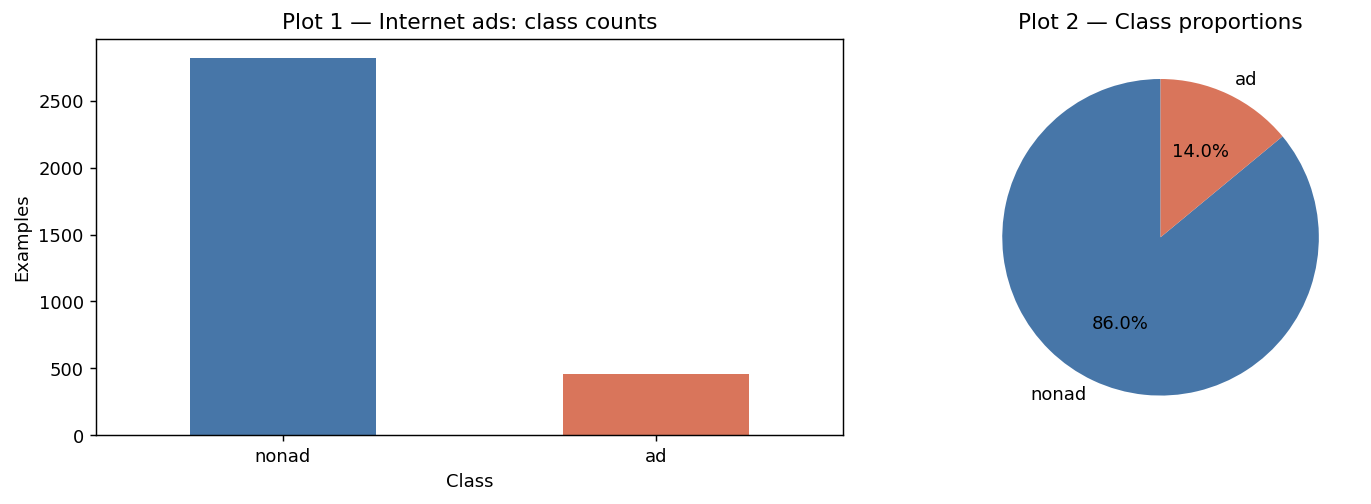

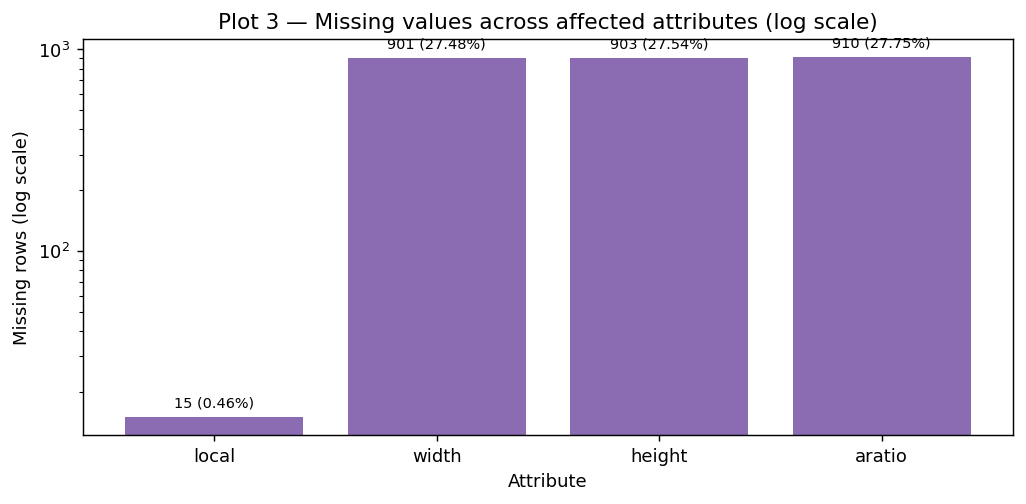

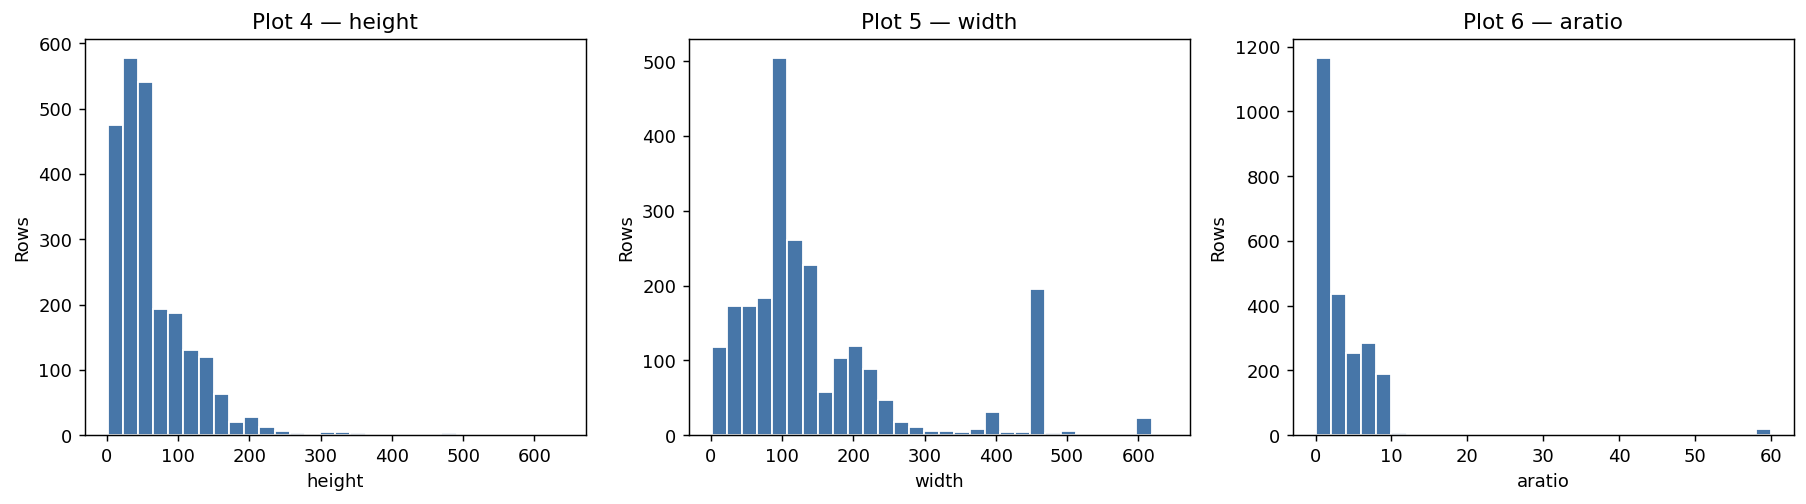

In [5]:
# Plots 1–2: class counts and class proportions.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

class_counts["count"].plot(kind="bar", ax=axes[0], color=["#4776A8", "#D9755B"])
axes[0].set_title("Plot 1 — Internet ads: class counts")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Examples")
axes[0].tick_params(axis="x", rotation=0)

class_counts["count"].plot(kind="pie", ax=axes[1], autopct="%1.1f%%", startangle=90,
                                colors=["#4776A8", "#D9755B"], ylabel="")
axes[1].set_title("Plot 2 — Class proportions")
plt.tight_layout()
plt.show()
majority_class = class_counts["count"].idxmax()
majority_pct = class_counts.loc[majority_class, "percent"]
minority_class = class_counts["count"].idxmin()
imbalance_ratio = class_counts.loc[majority_class, "count"] / class_counts.loc[minority_class, "count"]
print(f"Inference: {majority_class} is {majority_pct:.2f}% of rows; majority/minority ratio is {imbalance_ratio:.2f}:1.")
print("Metric implication: report ad precision, recall, F1 and ROC-AUC alongside accuracy because the ad class is the minority.")

# Plot 3: missing counts for every attribute with missing data.
missing_counts = data.isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(missing_counts.index, missing_counts.values, color="#8B6BB1")
ax.set_yscale("log")
ax.set_title("Plot 3 — Missing values across affected attributes (log scale)")
ax.set_xlabel("Attribute")
ax.set_ylabel("Missing rows (log scale)")
for bar, count in zip(bars, missing_counts.values):
    ax.annotate(f"{count} ({count / len(data):.2%})",
                (bar.get_x() + bar.get_width()/2, count), xytext=(0, 4),
                textcoords="offset points", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()
missing_geometry_rows = int(data[NUMERIC_FEATURES].isna().any(axis=1).sum())
missing_any_input_rows = int(data[feature_names].isna().any(axis=1).sum())
print(f"Inference: geometry is missing in {missing_geometry_rows} rows ({missing_geometry_rows / len(data):.2%}); any input is missing in {missing_any_input_rows} rows ({missing_any_input_rows / len(data):.2%}).")
print(f"The binary local field has {int(data['local'].isna().sum())} unknown entries; these are not zero-valued observations.")

# Plots 4–6: one histogram for each continuous geometry field.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for plot_number, (feature, ax) in enumerate(zip(NUMERIC_FEATURES, axes), start=4):
    values = data[feature].dropna()
    values.plot(kind="hist", bins=30, ax=ax, color="#4776A8", edgecolor="white")
    ax.set_title(f"Plot {plot_number} — {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Rows")
plt.tight_layout()
plt.show()
for feature in NUMERIC_FEATURES:
    values = data[feature].dropna()
    skew = values.skew()
    shape = "right-skewed" if skew > 0.5 else "left-skewed" if skew < -0.5 else "roughly symmetric"
    print(f"Inference ({feature}): {shape}; skew={skew:.3f}, median={values.median():.3g}, 95th percentile={values.quantile(.95):.3g}.")


## 4. Cleaning and feature-selection decisions

This pass normalizes types and labels without inventing values. We keep the raw table in `data`, make a separate `cleaned_data` copy, and defer imputation to model-specific pipelines so medians and modes are learned from training data only. The initial feature selection removes only constant columns; any supervised ranking will be fitted inside the training split to prevent leakage.


In [6]:
cleaned_data = data.copy()
for feature in feature_names:
    cleaned_data[feature] = pd.to_numeric(cleaned_data[feature], errors="coerce")
cleaned_data[TARGET] = cleaned_data[TARGET].astype("string").str.strip().str.rstrip(".")

valid_labels = {"ad", "nonad"}
observed_labels = set(cleaned_data[TARGET].dropna().unique())
invalid_labels = observed_labels - valid_labels
if invalid_labels:
    raise ValueError(f"Unexpected class labels: {sorted(invalid_labels)}")

invalid_binary_values = {}
for feature in BINARY_FEATURES:
    values = set(cleaned_data[feature].dropna().unique())
    unexpected = values - {0, 1}
    if unexpected:
        invalid_binary_values[feature] = sorted(unexpected)

# Feature-vector signatures let us identify duplicate patterns without confusing
# repeated examples with contradictory labels. They are also useful as split groups later.
feature_signatures = pd.util.hash_pandas_object(cleaned_data[feature_names], index=False)
signature_rows = pd.DataFrame({
    "signature": feature_signatures.to_numpy(),
    TARGET: cleaned_data[TARGET].to_numpy(),
})
signature_groups = signature_rows.groupby("signature", sort=False)
duplicate_signature_groups = signature_groups.size().gt(1)
conflicting_signature_groups = signature_groups[TARGET].nunique().gt(1)
rows_with_duplicate_signatures = int(feature_signatures.duplicated(keep=False).sum())
conflicting_signature_count = int(conflicting_signature_groups.sum())
conflicting_signature_rows = int(signature_groups.size()[conflicting_signature_groups].sum())

# Keep varying predictors; constant fields carry no information for a model.
nonconstant_features = [
    feature for feature in feature_names
    if cleaned_data[feature].nunique(dropna=True) > 1
]

print(f"Rows and columns: {cleaned_data.shape[0]:,} × {cleaned_data.shape[1]:,}")
print(f"Unexpected class labels: {sorted(invalid_labels)}")
print(f"Binary columns with values outside {{0, 1}}: {invalid_binary_values}")
print(f"Rows with at least one missing input: {int(cleaned_data[feature_names].isna().any(axis=1).sum()):,}")
print(f"Missing cells in binary indicators: {int(cleaned_data[BINARY_FEATURES].isna().sum().sum()):,}")
print(f"Exact duplicate rows including label: {int(cleaned_data.duplicated().sum()):,}")
print(f"Rows with a repeated feature signature: {rows_with_duplicate_signatures:,}")
print(f"Repeated feature-signature groups: {int(duplicate_signature_groups.sum()):,}")
print(f"Conflicting-label signature groups: {conflicting_signature_count:,} ({conflicting_signature_rows} rows)")
print(f"Nonconstant inputs retained: {len(nonconstant_features):,} / {len(feature_names):,}")


Rows and columns: 3,279 × 1,559
Unexpected class labels: []
Binary columns with values outside {0, 1}: {}
Rows with at least one missing input: 920
Missing cells in binary indicators: 15
Exact duplicate rows including label: 856
Rows with a repeated feature signature: 1,137
Repeated feature-signature groups: 278
Conflicting-label signature groups: 3 (54 rows)
Nonconstant inputs retained: 1,558 / 1,558


### Cleaning and feature-selection decisions

- Source labels are normalized and feature values are parsed according to `ad.names`; no source row or raw file is changed.
- Keep unknown values as missing in the audit and saved cleaned copy. The 15 missing `local` values are not converted to observed zeroes.
- The Decision Tree imputes continuous fields with training-partition medians and binary fields with training-partition modes. The test partition never fits its preprocessing.
- DBSCAN uses only the three geometry fields, median-imputed on the unlabeled geometry table for this descriptive unsupervised run, then `log1p` and IQR scaling before Euclidean distance.
- Primary Apriori/CHARM transactions include only feature items. Class tokens are added in separate runs for class-consequent rules.
- Preserve duplicates. Group identical full feature signatures before the supervised split; keep conflicting-label signatures and account for them.
- Only constant features would be removed; the raw audit found no constant inputs. The 18-item association alphabet is a support filter for tractable mining, not a predictive feature ranking.

## 5. Descriptive plots

The original audit cells show class balance, missingness, raw geometry histograms, class-wise boxplots, width-height scatter, binary-indicator prevalence, and geometry correlation. The integrated numbered plot index below adds course forms and task diagnostics; each has its own actual-data interpretation.

Inference (height): median ad=60, nonad=43; IQRs overlap.
Inference (width): median ad=460, nonad=101; IQRs overlap.
Inference (aratio): median ad=7.8, nonad=1.7241; IQRs overlap.
These are descriptive class differences; overlapping distributions mean geometry alone does not perfectly separate the labels.
Inference: width-height Spearman correlation is 0.411; ad and nonad median widths are 460 and 101 pixels, respectively.
Inference: most prevalent indicators: local=76.4%; url*images=28.8%; origurl*www.geocities.com=18.5%; origurl*geocities.com=18.5%; url*geocities.com=17.7%.
Inference: pairwise Pearson correlations: width–aratio=0.536; height–aratio=-0.285; height–width=0.181.
Correlations describe association, not causation.


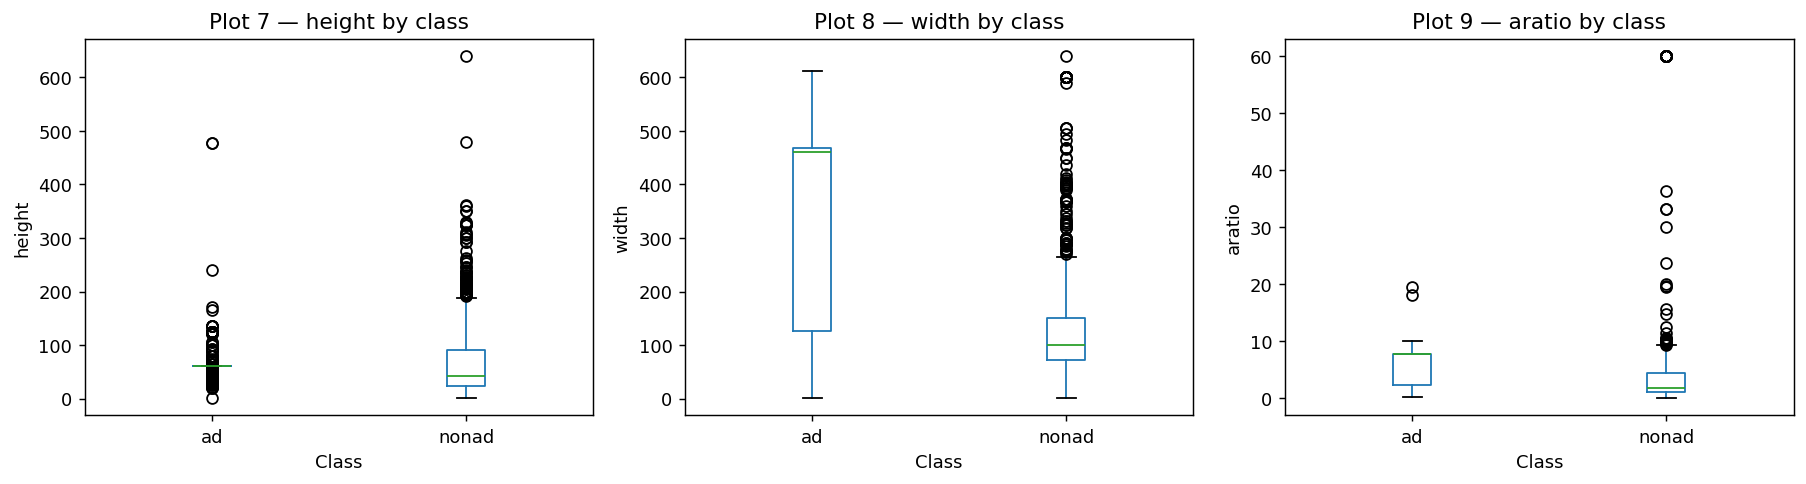

class,ad,nonad
height,60.0,43.0000
width,460.0,101.0000
aratio,7.8,1.7241


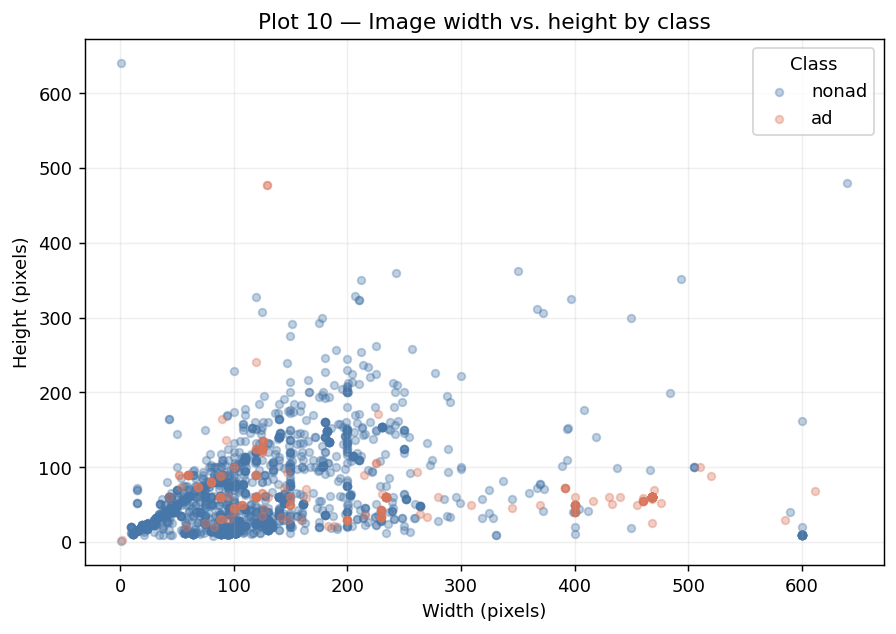

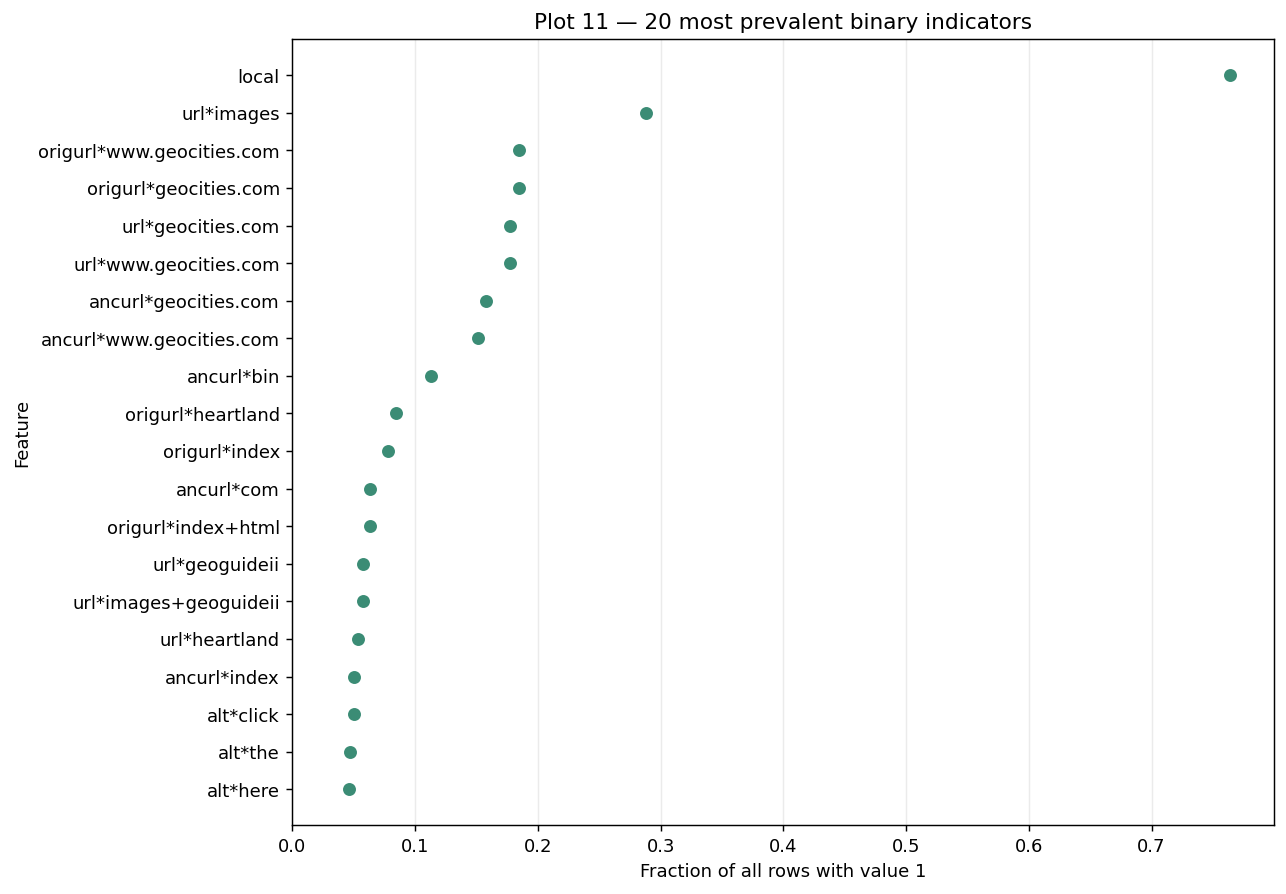

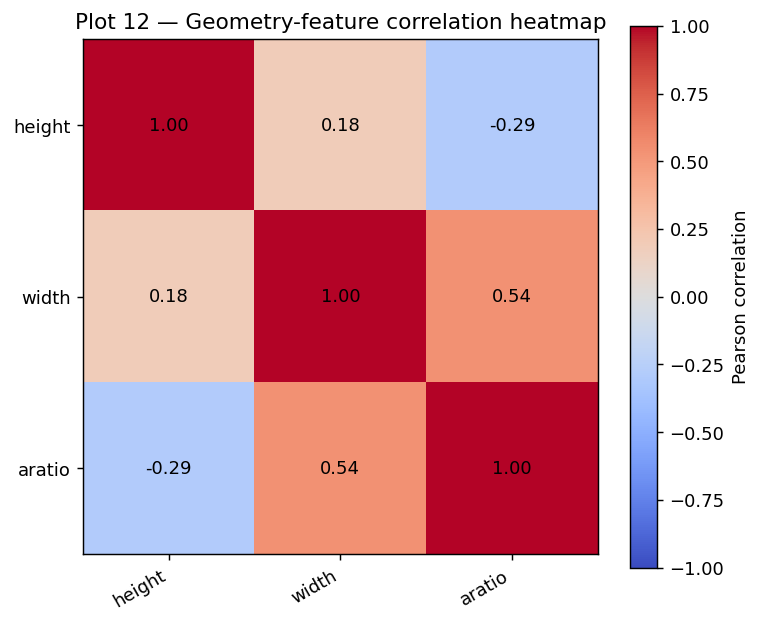

In [7]:
# Plots 7–9: compare the geometry distributions by class.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for plot_number, (feature, ax) in enumerate(zip(NUMERIC_FEATURES, axes), start=7):
    cleaned_data.boxplot(column=feature, by=TARGET, ax=ax, showfliers=True, grid=False)
    ax.set_title(f"Plot {plot_number} — {feature} by class")
    ax.set_xlabel("Class")
    ax.set_ylabel(feature)
plt.suptitle("")
plt.tight_layout()
plt.show()
class_medians = cleaned_data.groupby(TARGET)[NUMERIC_FEATURES].median().T
display(class_medians)
for feature in NUMERIC_FEATURES:
    by_class = cleaned_data.groupby(TARGET)[feature]
    ad_median = by_class.median().get("ad")
    nonad_median = by_class.median().get("nonad")
    ad_q1, ad_q3 = by_class.quantile(0.25).get("ad"), by_class.quantile(0.75).get("ad")
    nonad_q1, nonad_q3 = by_class.quantile(0.25).get("nonad"), by_class.quantile(0.75).get("nonad")
    iqr_overlap = max(ad_q1, nonad_q1) <= min(ad_q3, nonad_q3)
    print(f"Inference ({feature}): median ad={ad_median:g}, nonad={nonad_median:g}; IQRs {'overlap' if iqr_overlap else 'do not overlap'}.")
print("These are descriptive class differences; overlapping distributions mean geometry alone does not perfectly separate the labels.")

# Plot 10: image width and height, colored by the known class.
scatter_data = cleaned_data[["width", "height", TARGET]].dropna()
fig, ax = plt.subplots(figsize=(7, 5))
for label, color in [("nonad", "#4776A8"), ("ad", "#D9755B")]:
    group = scatter_data[scatter_data[TARGET] == label]
    ax.scatter(group["width"], group["height"], s=18, alpha=0.35, label=label, color=color)
ax.set_title("Plot 10 — Image width vs. height by class")
ax.set_xlabel("Width (pixels)")
ax.set_ylabel("Height (pixels)")
ax.legend(title="Class")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()
rank_corr = scatter_data[["width", "height"]].corr(method="spearman").iloc[0, 1]
print(f"Inference: width-height Spearman correlation is {rank_corr:.3f}; ad and nonad median widths are {class_medians.loc['width', 'ad']:g} and {class_medians.loc['width', 'nonad']:g} pixels, respectively.")

# Plot 11: course-style dot plot of the most common binary indicators.
feature_prevalence = (cleaned_data[BINARY_FEATURES] == 1).sum() / len(cleaned_data)
feature_prevalence = feature_prevalence.sort_values(ascending=False).head(20).sort_values()
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(feature_prevalence.values, feature_prevalence.index, color="#3B8C75", s=38)
ax.set_title("Plot 11 — 20 most prevalent binary indicators")
ax.set_xlabel("Fraction of all rows with value 1")
ax.set_ylabel("Feature")
ax.set_xlim(left=0)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()
top_indicators = feature_prevalence.sort_values(ascending=False).head(5)
print("Inference: most prevalent indicators: " + "; ".join(f"{name}={value:.1%}" for name, value in top_indicators.items()) + ".")

# Plot 12: correlations among the three continuous geometry features.
geometry_corr = cleaned_data[NUMERIC_FEATURES].corr()
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(geometry_corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUMERIC_FEATURES)))
ax.set_xticklabels(NUMERIC_FEATURES, rotation=30, ha="right")
ax.set_yticks(range(len(NUMERIC_FEATURES)))
ax.set_yticklabels(NUMERIC_FEATURES)
for row in range(len(NUMERIC_FEATURES)):
    for column in range(len(NUMERIC_FEATURES)):
        ax.text(column, row, f"{geometry_corr.iloc[row, column]:.2f}", ha="center", va="center", color="black")
ax.set_title("Plot 12 — Geometry-feature correlation heatmap")
fig.colorbar(image, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()
correlation_pairs = [
    (abs(geometry_corr.iloc[i, j]), NUMERIC_FEATURES[i], NUMERIC_FEATURES[j], geometry_corr.iloc[i, j])
    for i in range(len(NUMERIC_FEATURES)) for j in range(i + 1, len(NUMERIC_FEATURES))
]
correlation_pairs.sort(reverse=True)
print("Inference: pairwise Pearson correlations: " + "; ".join(f"{left}–{right}={value:.3f}" for _, left, right, value in correlation_pairs) + ".")
print("Correlations describe association, not causation.")


### Visualization interpretation

The report figure manifest contains a specific interpretation for every figure. It includes count/proportion views; missingness and feature distribution plots; association-rule and CHARM summaries; holdout confusion/ROC/tree views; and DBSCAN parameter/cluster views. Supplementary diagnostics are labeled separately from the course forms.

## Integrated checkpoint

The original descriptive audit has been extended with target-separated association analysis, a grouped Decision Tree evaluation, feature-only DBSCAN, measured local/PySpark comparisons, individual plot interpretations, and reproducibility details. The separate PDF report and source bundle are built from these same artifacts.

## 6. Saved preprocessing and repeated signatures

The cleaned copy below normalizes feature types and labels but retains every row and every missing value. Task-specific imputation is fitted only where the analysis requires it: on training rows for the Decision Tree, and on the unlabeled geometry table for descriptive DBSCAN. `preprocessing_config.json` records those choices and the raw-file SHA-256 manifest.

In [8]:
from pathlib import Path
import json
import pandas as pd

PREPROCESSED_DIR = WORK_DIR / "artifacts" / "processed"
preprocessing_config = json.loads((PREPROCESSED_DIR / "preprocessing_config.json").read_text())
cleaned_saved = pd.read_csv(PREPROCESSED_DIR / "internet_ads_cleaned.csv")
signature_ledger = pd.read_csv(PREPROCESSED_DIR / "feature_signature_ledger.csv")
repeats = preprocessing_config["repeated_feature_signatures"]
print(f"Saved cleaned copy: {cleaned_saved.shape[0]:,} rows × {cleaned_saved.shape[1]:,} columns")
print(f"Missing feature cells preserved: {int(cleaned_saved[feature_names].isna().sum().sum()):,}")
print(f"Distinct full-feature signatures: {repeats['distinct_signatures']:,}")
print(f"Repeated signature groups: {repeats['groups_with_repeated_rows']:,}; rows in those groups: {repeats['rows_in_repeated_groups']:,}; excess rows: {repeats['extra_rows_beyond_first_per_signature']:,}")
print(f"Conflicting-label signature groups: {repeats['groups_with_conflicting_labels']}")
print("No repeated row was dropped. The row-level ledger is saved beside the cleaned copy.")
display(cleaned_saved[[*NUMERIC_FEATURES, "local", TARGET]].head())

Saved cleaned copy: 3,279 rows × 1,559 columns
Missing feature cells preserved: 2,729
Distinct full-feature signatures: 2,420
Repeated signature groups: 278; rows in those groups: 1,137; excess rows: 859
Conflicting-label signature groups: 3
No repeated row was dropped. The row-level ledger is saved beside the cleaned copy.


,height,width,aratio,local,class
0,125.0,125.0,1.0000,1.0,ad
1,57.0,468.0,8.2105,1.0,ad
2,33.0,230.0,6.9696,1.0,ad
3,60.0,468.0,7.8000,1.0,ad
4,60.0,468.0,7.8000,1.0,ad


## 7. Apriori and CHARM: feature mining separated from class rules

Each raw row is a transaction, including repeated signatures. The three continuous geometry columns are excluded rather than binned. The primary Apriori and CHARM runs use feature-only transactions. Separate target-augmented runs produce class-consequent rules; this keeps `class` out of the unsupervised itemsets. At 5% support the minimum count is 164 rows, and rule confidence is at least 60%.

In [9]:
ASSOCIATION_DIR = WORK_DIR / "artifacts" / "association"
association_metadata = json.loads((ASSOCIATION_DIR / "association_metadata.json").read_text())
feature_mining = association_metadata["feature_only_mining"]
class_mining = association_metadata["class_association_rule_mining"]
feature_itemsets = pd.read_csv(ASSOCIATION_DIR / "apriori_itemsets.csv")
feature_rules = pd.read_csv(ASSOCIATION_DIR / "apriori_rules.csv")
class_rules = pd.read_csv(ASSOCIATION_DIR / "apriori_class_rules.csv")
closed_itemsets = pd.read_csv(ASSOCIATION_DIR / "charm_closed_itemsets.csv")
charm_class_rules = pd.read_csv(ASSOCIATION_DIR / "charm_class_rules.csv")
print(f"Transactions: {association_metadata['rows_as_transactions']:,}; selected feature items: {association_metadata['selected_binary_feature_count']}")
print(f"Feature-only Apriori: {len(feature_itemsets):,} itemsets, {len(feature_rules):,} rules; runtime {feature_mining['apriori_runtime_seconds_excluding_transaction_build']:.6f} s")
print(f"Feature-only CHARM: {len(closed_itemsets):,} closed itemsets; exhaustive verification={feature_mining['charm_exhaustive_verification']['matches_exhaustive']}")
print(f"Separate target-augmented Apriori: {len(class_rules):,} class-consequent rules from {class_mining['apriori_itemset_count']:,} itemsets")
print(f"Separate target-augmented CHARM: {len(charm_class_rules):,} class rules from {class_mining['charm_class_augmented_closed_itemset_count']:,} closures; exhaustive verification={class_mining['charm_exhaustive_verification']['matches_exhaustive']}")
print("Top class-consequent Apriori rules, ranked by lift:")
display(class_rules[["antecedent_text", "consequent_text", "support_count", "support", "confidence", "lift"]].head(8))
print("Feature-only Apriori rules:")
display(feature_rules[["antecedent_text", "consequent_text", "support_count", "support", "confidence", "lift"]].head(5))

Transactions: 3,279; selected feature items: 18
Feature-only Apriori: 1,194 itemsets, 44,122 rules; runtime 0.011651 s
Feature-only CHARM: 41 closed itemsets; exhaustive verification=True
Separate target-augmented Apriori: 1,190 class-consequent rules from 2,388 itemsets
Separate target-augmented CHARM: 37 class rules from 80 closures; exhaustive verification=True
Top class-consequent Apriori rules, ranked by lift:
Feature-only Apriori rules:


,antecedent_text,consequent_text,support_count,support,confidence,lift
0,ancurl*com=1,class=ad,189,0.05764,0.913043,6.522592
1,url*images+geoguideii=1,class=nonad,189,0.05764,1.000000,1.162766
2,url*geoguideii=1,class=nonad,189,0.05764,1.000000,1.162766
3,url*geocities.com=1 AND url*geoguideii=1,class=nonad,189,0.05764,1.000000,1.162766
4,url*geoguideii=1 AND url*images+geoguideii=1,class=nonad,189,0.05764,1.000000,1.162766
5,origurl*www.geocities.com=1 AND url*images+geoguideii=1,class=nonad,189,0.05764,1.000000,1.162766
6,url*geoguideii=1 AND url*www.geocities.com=1,class=nonad,189,0.05764,1.000000,1.162766
7,url*geoguideii=1 AND url*images=1,class=nonad,189,0.05764,1.000000,1.162766


,antecedent_text,consequent_text,support_count,support,confidence,lift
0,url*geoguideii=1,url*images+geoguideii=1,189,0.05764,1.0,17.349206
1,url*images+geoguideii=1,url*geoguideii=1,189,0.05764,1.0,17.349206
2,url*geoguideii=1,url*images+geoguideii=1 AND url*www.geocities.com=1,189,0.05764,1.0,17.349206
3,url*images+geoguideii=1,url*geoguideii=1 AND url*www.geocities.com=1,189,0.05764,1.0,17.349206
4,url*geoguideii=1 AND url*www.geocities.com=1,url*images+geoguideii=1,189,0.05764,1.0,17.349206


In [10]:
support_sensitivity = pd.read_csv(ASSOCIATION_DIR / "apriori_support_sensitivity.csv")
print("Sensitivity runs cap the union itemset at length 3; the primary runs are unlimited length.")
display(support_sensitivity)

Sensitivity runs cap the union itemset at length 3; the primary runs are unlimited length.


,min_support,minimum_count,feature_frequent_singletons,feature_frequent_pairs,feature_frequent_triples,feature_itemsets_through_length_3,class_rules_at_confidence_0_60_max_len_3,feature_only_runtime_seconds,class_augmented_runtime_seconds,max_len
0,0.02,66,87,456,1568,2111,531,0.024617,0.017212,3
1,0.03,99,31,127,343,501,143,0.001788,0.002363,3
2,0.05,164,18,61,152,231,75,0.000683,0.000939,3
3,0.08,263,10,26,41,77,33,0.000198,0.000305,3


### Sequential-pattern requirement: structural analysis and separate synthetic demo

The Internet Ads file has no timestamp, session identifier, or natural event order, so it cannot support temporal or session-based sequence claims. A separate data-derived analysis orders active indicators by the URL-named field families `origurl → ancurl → url`; this is an analyst-defined structural order, not observed chronology, and may not satisfy a rubric requiring temporal sequences. The five-sequence GSP example below is synthetic and remains separate from the dataset.

In [11]:
toy_sequence = association_metadata["toy_sequential_demo"]
toy_patterns = pd.read_csv(ASSOCIATION_DIR / "toy_sequential_patterns.csv")
print(f"Synthetic sequences: {toy_sequence['sequence_count']}; minimum support={toy_sequence['parameters']['min_support']:.0%} ({toy_sequence['parameters']['min_support_count']} sequences); patterns={len(toy_patterns)}")
print("Hand-authored toy sequences:")
for i, sequence in enumerate(toy_sequence["sequences"], start=1):
    print(f"  {i}: {' → '.join(sequence)}")
display(toy_patterns.head(12))

Synthetic sequences: 5; minimum support=40% (2 sequences); patterns=14
Hand-authored toy sequences:
  1: view → search → click → purchase
  2: view → search → click
  3: search → click → purchase
  4: view → click → purchase
  5: view → search → purchase


,pattern,length,support_count,support,source
0,click,1,4,0.8,synthetic toy only; not Internet Ads data
1,purchase,1,4,0.8,synthetic toy only; not Internet Ads data
2,search,1,4,0.8,synthetic toy only; not Internet Ads data
3,view,1,4,0.8,synthetic toy only; not Internet Ads data
4,click -> purchase,2,3,0.6,synthetic toy only; not Internet Ads data
5,search -> click,2,3,0.6,synthetic toy only; not Internet Ads data
6,search -> purchase,2,3,0.6,synthetic toy only; not Internet Ads data
7,view -> click,2,3,0.6,synthetic toy only; not Internet Ads data
8,view -> purchase,2,3,0.6,synthetic toy only; not Internet Ads data
9,view -> search,2,3,0.6,synthetic toy only; not Internet Ads data


## 8. Decision Tree: grouped holdout, train-only preprocessing, and rules

All copies of the same full input signature stay in one partition. Median imputation for geometry and mode imputation for binary fields are fitted on training rows only; the test set is not used to fit preprocessing. Balanced class weights address the ad/nonad imbalance. Rule probabilities below are the predicted class share of class-weighted training mass at a leaf, not the unweighted fraction of ads.

In [12]:
MODEL_DIR = WORK_DIR / "artifacts" / "models"
model_summary = json.loads((MODEL_DIR / "classification_clustering_summary.json").read_text())
tree_result = model_summary["decision_tree"]
print(f"Split: {tree_result['n_train']:,} train / {tree_result['n_test']:,} test; feature-signature overlap={tree_result['split']['signature_overlap']}")
print("Preprocessing:", tree_result["preprocessing"])
print("Parameters:", tree_result["tree_parameters"])
for metric in ["accuracy", "balanced_accuracy", "precision_ad", "recall_ad", "f1_ad", "roc_auc"]:
    print(f"{metric}: {tree_result[metric]:.4f}")
print("Confusion matrix (actual nonad/ad by predicted nonad/ad):", tree_result["confusion_matrix_labels_nonad_ad"])
tree_rules = pd.read_csv(MODEL_DIR / "decision_tree_if_then_rules.csv")
print(f"Extracted IF-THEN leaf rules: {len(tree_rules)}")
display(tree_rules[["rule_id", "if", "then", "training_rows_at_leaf", "weighted_predicted_class_probability_at_leaf"]])

Split: 2,623 train / 656 test; feature-signature overlap=0
Preprocessing: {'continuous': 'training-partition median imputation', 'binary': 'training-partition most-frequent imputation', 'scaling': 'none (CART split thresholds do not require feature scaling)'}
Parameters: {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 20, 'class_weight': 'balanced', 'random_state': 42}
accuracy: 0.9192
balanced_accuracy: 0.8848
precision_ad: 0.6696
recall_ad: 0.8370
f1_ad: 0.7440
roc_auc: 0.9116
Confusion matrix (actual nonad/ad by predicted nonad/ad): [[526, 38], [15, 77]]
Extracted IF-THEN leaf rules: 12


,rule_id,if,then,training_rows_at_leaf,weighted_predicted_class_probability_at_leaf
0,1,ancurl*com = 0 AND width <= 390.5 AND url*ads = 0 AND alt*click = 0 AND url*graphics = 0,nonad,2223,0.835482
1,2,ancurl*com = 0 AND width <= 390.5 AND url*ads = 0 AND alt*click = 0 AND url*graphics = 1,ad,38,0.656089
2,3,ancurl*com = 0 AND width <= 390.5 AND url*ads = 0 AND alt*click = 1,ad,31,0.795183
3,4,ancurl*com = 0 AND width <= 390.5 AND url*ads = 1,ad,28,0.980853
4,5,ancurl*com = 0 AND width > 390.5 AND width <= 485 AND width <= 455,ad,24,0.786702
5,6,ancurl*com = 0 AND width > 390.5 AND width <= 485 AND width > 455 AND ancurl*bin = 0,ad,49,0.989502
6,7,ancurl*com = 0 AND width > 390.5 AND width <= 485 AND width > 455 AND ancurl*bin = 1,ad,38,1.000000
7,8,ancurl*com = 0 AND width > 390.5 AND width > 485,nonad,25,0.651664
8,9,ancurl*com = 1 AND height <= 53.5,ad,40,0.972093
9,10,ancurl*com = 1 AND height > 53.5 AND ancurl*bin = 0,ad,81,1.000000


## 9. DBSCAN: geometry distance, epsilon, noise, and sensitivity

DBSCAN uses height, width, and aspect ratio only. After median imputation, `log1p` and RobustScaler place the three differently scaled/skewed fields on comparable IQR scales; Euclidean distance is then used. A 10-neighbor distance-curve knee chose epsilon. Class is excluded from fitting and appears only in post-hoc profile/ARI results. The parameter sweep is included because DBSCAN assignments are sensitive to epsilon and `min_samples`.

In [13]:
dbscan_result = model_summary["dbscan"]
print("Distance:", dbscan_result["distance"])
print(f"epsilon={dbscan_result['eps_selected']:.6f}; min_samples={dbscan_result['min_samples_selected']}; clusters={dbscan_result['clusters_excluding_noise']}")
print(f"Noise: {dbscan_result['noise_count']} / {dbscan_result['rows_clustered']} ({dbscan_result['noise_fraction']:.2%})")
print(f"Sampled non-noise silhouette={dbscan_result['silhouette_non_noise_sampled']:.4f}; post-hoc ARI vs class={dbscan_result['adjusted_rand_vs_class_all_rows_posthoc']:.4f}")
dbscan_sensitivity = pd.read_csv(MODEL_DIR / "dbscan_parameter_sensitivity.csv")
cluster_profile = pd.read_csv(MODEL_DIR / "dbscan_cluster_class_profile.csv")
noise_points = pd.read_csv(MODEL_DIR / "dbscan_noise_points.csv")
print("Parameter sensitivity:")
display(dbscan_sensitivity)
print("Cluster sizes and post-hoc class profile:")
display(cluster_profile)
print(f"Saved noise-point rows: {len(noise_points)}")
display(noise_points.head(10))

Distance: Euclidean after log1p and RobustScaler (IQR scaling) on median-imputed geometry
epsilon=0.457798; min_samples=10; clusters=3
Noise: 70 / 3279 (2.13%)
Sampled non-noise silhouette=0.4991; post-hoc ARI vs class=-0.0240
Parameter sensitivity:
Cluster sizes and post-hoc class profile:
Saved noise-point rows: 70


,sensitivity_axis,eps,eps_multiplier,min_samples,n_clusters_excluding_noise,noise_count,noise_fraction,silhouette_non_noise_sampled,adjusted_rand_vs_class_all_rows_posthoc,adjusted_rand_vs_class_non_noise_posthoc
0,epsilon,0.343348,0.75,10,5,117,0.035682,0.351722,0.406230,0.486893
1,epsilon,0.457798,1.00,10,3,70,0.021348,0.499115,-0.024001,-0.017561
2,epsilon,0.572247,1.25,10,3,52,0.015858,0.493616,-0.019943,-0.017478
3,epsilon,0.686697,1.50,10,3,42,0.012809,0.492690,-0.018977,-0.017430
4,min_samples,0.457798,1.00,6,4,55,0.016773,0.483818,-0.023595,-0.020222
5,min_samples,0.457798,1.00,10,3,70,0.021348,0.499115,-0.024001,-0.017561
6,min_samples,0.457798,1.00,15,3,77,0.023483,0.510720,-0.026661,-0.017590


,cluster,ad,nonad,All
0,-1,7,63,70
1,0,452,2721,3173
2,1,0,20,20
3,2,0,16,16
4,All,459,2820,3279


,row_position,cluster,class_for_posthoc_profile_only,raw_height,raw_width,raw_aratio
0,19,-1,ad,30.0,585.0,19.5000
1,67,-1,ad,2.0,2.0,1.0000
2,132,-1,ad,26.0,468.0,18.0000
3,308,-1,ad,477.0,129.0,0.2704
4,311,-1,ad,477.0,129.0,0.2704
5,416,-1,ad,100.0,510.0,5.1000
6,420,-1,ad,68.0,612.0,9.0000
7,483,-1,nonad,12.0,234.0,19.5000
8,486,-1,nonad,15.0,NaN,NaN
9,640,-1,nonad,8.0,82.0,10.2500


## 10. PySpark implementations and measured execution status

The source includes PySpark `DecisionTreeClassifier` on the same grouped split and train-only transformed matrices as scikit-learn, plus Spark FP-Growth on the same class-augmented row transactions and thresholds as local Apriori. Both PySpark workloads executed in local mode. On this small dataset, Spark was slower than the matched local baselines; startup and conversion costs are reported separately.

In [14]:
SPARK_DIR = WORK_DIR / "artifacts" / "spark"
spark_summary = json.loads((SPARK_DIR / "pyspark_benchmark_summary.json").read_text())
local_tree = spark_summary["local_tree"]
local_apriori = spark_summary["local_apriori"]
print(f"Spark status: {spark_summary['status']}; PySpark {spark_summary['pyspark_version']}; master={spark_summary['spark_master']}")
startup_s = spark_summary.get("spark_startup_seconds", spark_summary.get("spark_startup_attempt_seconds"))
tasks_completed = spark_summary.get("spark_tasks_completed", spark_summary["status"] == "completed")
print(f"Spark startup: {startup_s:.3f} s; both workloads completed={tasks_completed}")
if spark_summary["status"] == "completed":
    spark_tree = spark_summary["spark_tree"]
    spark_fp = spark_summary["spark_fpgrowth"]
    tree_e2e = spark_summary["tree_timing_comparison"]["spark_end_to_end_excluding_startup_seconds"]
    fp_e2e = spark_summary["arm_timing_comparison"]["spark_fp_end_to_end_excluding_startup_seconds"]
    local_tree_e2e = local_tree["fit_seconds_median"] + local_tree["predict_seconds_median"]
    local_fp = local_apriori["elapsed_seconds"]
    comparison = pd.DataFrame([
        {"Task": "Decision Tree fit", "Local (s)": local_tree["fit_seconds_median"], "Spark (s)": spark_tree["fit_seconds_median"], "Spark/local": spark_tree["fit_seconds_median"] / local_tree["fit_seconds_median"]},
        {"Task": "Tree fit + predict/materialization", "Local fit+predict (s)": local_tree_e2e, "Spark end-to-end excluding startup (s)": tree_e2e, "Spark/local": tree_e2e / local_tree_e2e},
        {"Task": "Apriori vs FP-Growth fit", "Local Apriori (s)": local_fp, "Spark FP-Growth fit (s)": spark_fp["fit_seconds_median"], "Spark/local": spark_fp["fit_seconds_median"] / local_fp},
        {"Task": "Apriori vs FP-Growth end-to-end", "Local Apriori (s)": local_fp, "Spark FP-Growth including conversion/collection (s)": fp_e2e, "Spark/local": fp_e2e / local_fp},
    ])
    display(comparison)
    print(f"Tree Spark conversion/materialization: {spark_tree['spark_dataframe_conversion_and_materialization_seconds']:.3f} s; FP-Growth conversion/materialization: {spark_fp['spark_dataframe_conversion_and_materialization_seconds']:.3f} s; itemset/rule collection: {spark_fp['collect_itemsets_and_rules_seconds_median']:.3f} s.")
    print("Observed result: Spark was slower on this dataset. Spark startup is reported separately. FP-Growth and Apriori are different algorithms, so the association comparison is task-level.")
    print("Spark Decision Tree metrics:", spark_tree["metrics"])
    print("Matched local Decision Tree metrics:", local_tree["metrics"])
    print(f"Association outputs: local Apriori={local_apriori['frequent_itemset_count']:,} itemsets / {local_apriori['association_rule_count']:,} all-consequent rules; Spark FP-Growth={spark_fp['frequent_itemset_count']:,} itemsets / {spark_fp['association_rule_count']:,} singleton-consequent rules.")
    print("The 11,709 singleton-consequent local rules match Spark's rule set; the larger local total includes multi-item consequents.")
else:
    print(f"Spark tasks did not run: {spark_summary.get('spark_error', 'gateway initialization failed')}.")
    print("No Spark workload metric or local-vs-Spark performance conclusion is available.")

Spark status: completed; PySpark 3.5.3; master=local[2]
Spark startup: 1.525 s; both workloads completed=True
Tree Spark conversion/materialization: 4.726 s; FP-Growth conversion/materialization: 0.113 s; itemset/rule collection: 0.262 s.
Observed result: Spark was slower on this dataset. Spark startup is reported separately. FP-Growth and Apriori are different algorithms, so the association comparison is task-level.
Spark Decision Tree metrics: {'accuracy': 0.9207317073170732, 'balanced_accuracy': 0.8902251002158494, 'confusion_matrix_labels_0_nonad_1_ad': [[526, 38], [14, 78]], 'f1_ad': 0.75, 'precision_ad': 0.6724137931034483, 'recall_ad': 0.8478260869565217, 'roc_auc_ad': 0.9058067375886525}
Matched local Decision Tree metrics: {'accuracy': 0.9192073170731707, 'balanced_accuracy': 0.8847903176071539, 'confusion_matrix_labels_0_nonad_1_ad': [[526, 38], [15, 77]], 'f1_ad': 0.7439613526570048, 'precision_ad': 0.6695652173913044, 'recall_ad': 0.8369565217391305, 'roc_auc_ad': 0.9116076

,Task,Local (s),Spark (s),Spark/local,Local fit+predict (s),Spark end-to-end excluding startup (s),Local Apriori (s),Spark FP-Growth fit (s),Spark FP-Growth including conversion/collection (s)
0,Decision Tree fit,0.030632,0.865233,28.245839,NaN,NaN,NaN,NaN,NaN
1,Tree fit + predict/materialization,NaN,NaN,176.240129,0.032342,5.699972,NaN,NaN,NaN
2,Apriori vs FP-Growth fit,NaN,NaN,1.875052,NaN,NaN,0.037974,0.071203,NaN
3,Apriori vs FP-Growth end-to-end,NaN,NaN,11.742583,NaN,NaN,0.037974,NaN,0.445911


### 10.1 Feature selection and cleaning sensitivity

The ANOVA filter (`SelectKBest`, `k=100`) was fit on the training partition only and compared on the same grouped holdout as the all-feature tree. This is one holdout comparison, not cross-validated feature-selection evidence. The conflicting-label sensitivity copy excludes 54 rows from three exact feature-signature groups, but that screening uses target labels across the full file; it is not the primary analysis. IQR flags are review indicators, and all 363 flagged rows remain in the primary data.

Conflict sensitivity only: 3 groups / 54 rows excluded; primary data unchanged.
IQR geometry review: 363 rows flagged and 0 deleted.


,Features,accuracy,balanced_accuracy,precision_ad,recall_ad,f1_ad,roc_auc
Model,,,,,,,
All input features,1558,0.919207,0.88479,0.669565,0.836957,0.743961,0.911608
Top 100 ANOVA features,100,0.942073,0.89354,0.775510,0.826087,0.800000,0.909449


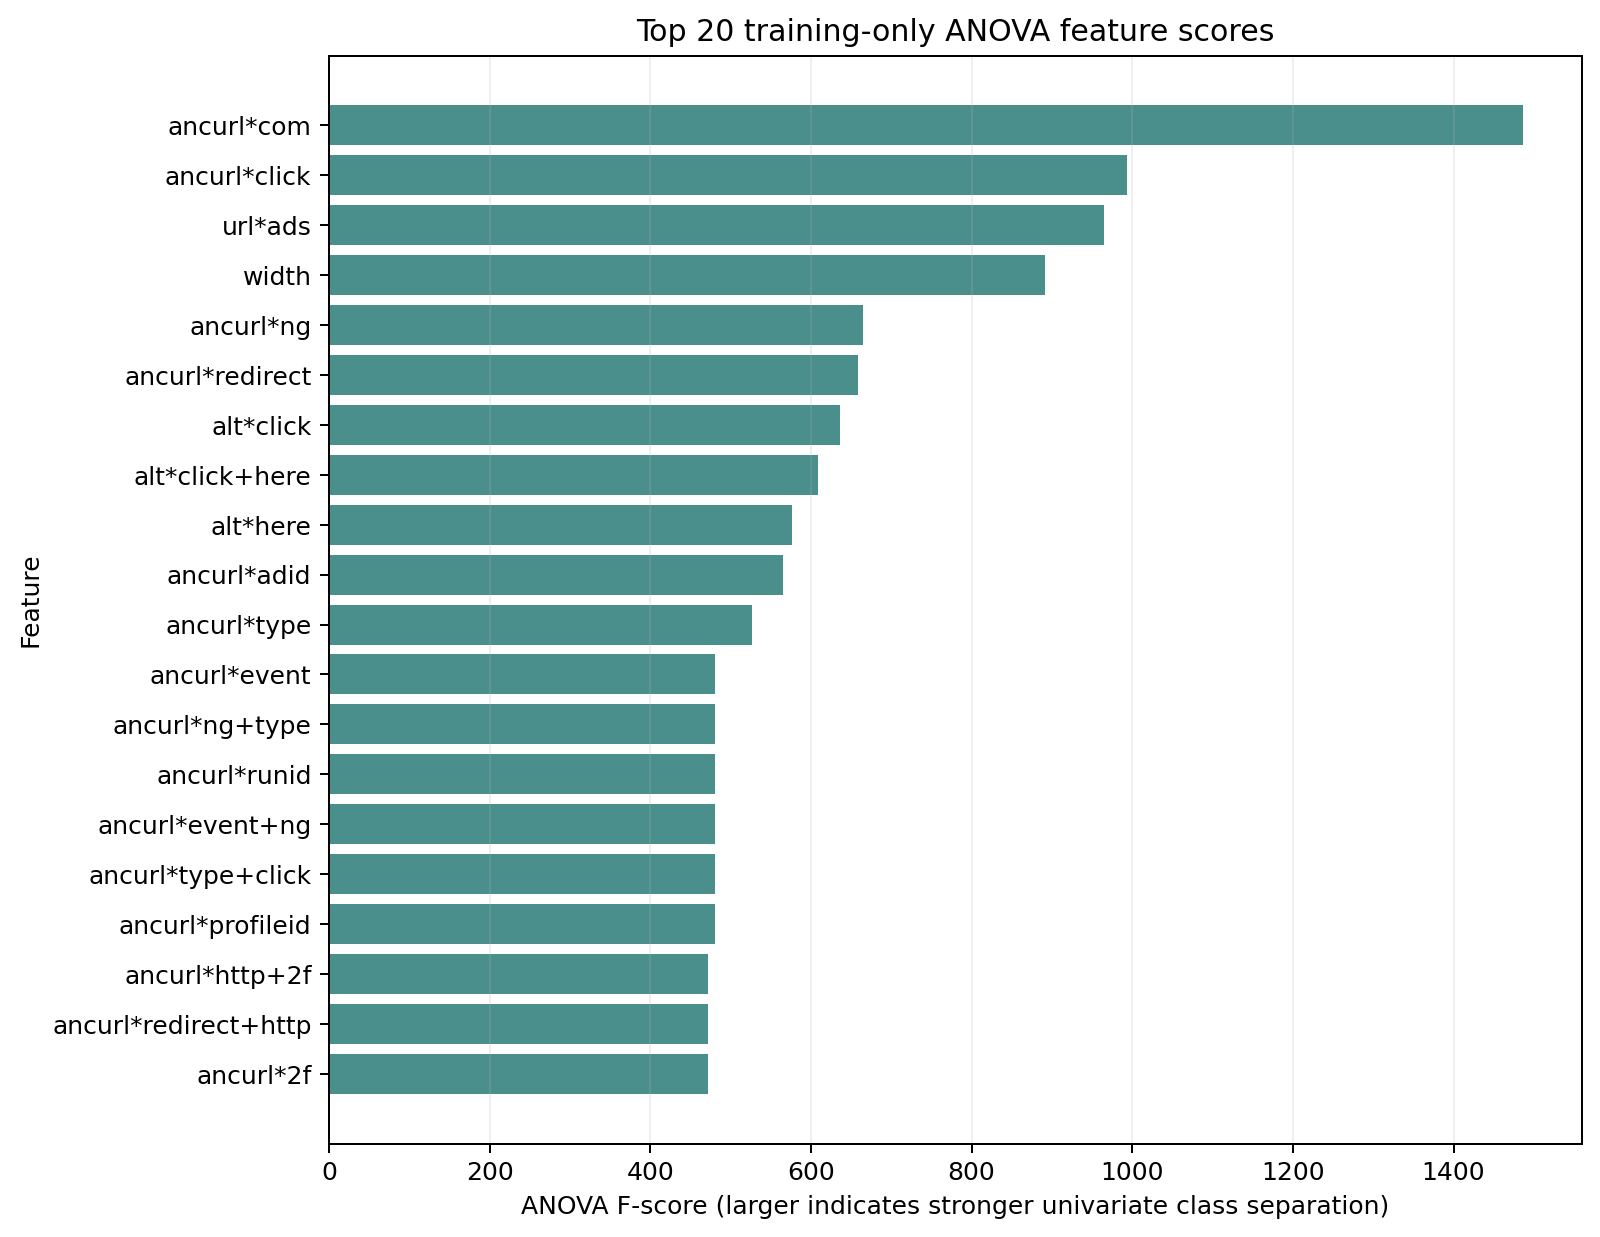

In [15]:
SENSITIVITY_DIR = WORK_DIR / "artifacts" / "models" / "preprocessing_sensitivity"
sensitivity = json.loads((SENSITIVITY_DIR / "preprocessing_sensitivity.json").read_text())
selection = sensitivity["classification_feature_selection"]
metric_names = ["accuracy", "balanced_accuracy", "precision_ad", "recall_ad", "f1_ad", "roc_auc"]
selection_rows = []
for label, result in [("All input features", selection["baseline_all_features"]), ("Top 100 ANOVA features", selection["selected_top_100"])]:
    row = {"Model": label, "Features": result["selected_feature_count"]}
    row.update({metric: result["metrics"][metric] for metric in metric_names})
    selection_rows.append(row)
display(pd.DataFrame(selection_rows).set_index("Model"))
conflicts = sensitivity["conflicting_label_cleaning_sensitivity"]
iqr_review = sensitivity["geometry_iqr_review"]
print(f"Conflict sensitivity only: {conflicts['conflict_groups']} groups / {conflicts['rows_excluded']} rows excluded; primary data unchanged.")
print(f"IQR geometry review: {iqr_review['rows_flagged_any']} rows flagged and {iqr_review['rows_deleted']} deleted.")
from IPython.display import Image, display
display(Image(filename=str(SENSITIVITY_DIR / "anova_feature_scores_top20.png")))

### 10.2 Dataset-derived URL-family pattern analysis

Each of the 3,279 actual rows is represented as three ordered sets of active binary indicators from `origurl`, `ancurl`, and `url`. The 16 selected items produced 71 frequent structural patterns and 29 prefix-extension rules at 5% support and 60% confidence (maximum length 3). The order is an explicit schema assumption; the source has neither raw URLs nor chronology, so these are not temporal findings.

Rows represented: 3,279; selected items: 16; frequent patterns: 71; prefix-extension rules: 29.
Order: origurl → ancurl → url
Temporal sequence requirement fulfilled: False


,antecedent_schema_pattern,antecedent_source_roles,consequent_schema_item,source_role_order,sequence_support_count,sequence_support,prefix_support_count,confidence,lift,is_temporal
1,origurl:heartland → ancurl:geocities.com,origurl → ancurl,url:geocities.com,origurl → ancurl → url,222,0.067704,222,1.000000,5.643718,False
2,origurl:heartland → ancurl:geocities.com,origurl → ancurl,url:www.geocities.com,origurl → ancurl → url,222,0.067704,222,1.000000,5.643718,False
3,origurl:heartland → ancurl:www.geocities.com,origurl → ancurl,url:geocities.com,origurl → ancurl → url,214,0.065264,214,1.000000,5.643718,False
4,origurl:heartland → ancurl:www.geocities.com,origurl → ancurl,url:www.geocities.com,origurl → ancurl → url,214,0.065264,214,1.000000,5.643718,False
5,origurl:geocities.com → ancurl:geocities.com,origurl → ancurl,url:geocities.com,origurl → ancurl → url,473,0.144251,474,0.997890,5.631811,False
6,origurl:geocities.com → ancurl:geocities.com,origurl → ancurl,url:www.geocities.com,origurl → ancurl → url,473,0.144251,474,0.997890,5.631811,False
7,origurl:www.geocities.com → ancurl:geocities.com,origurl → ancurl,url:geocities.com,origurl → ancurl → url,473,0.144251,474,0.997890,5.631811,False
8,origurl:www.geocities.com → ancurl:geocities.com,origurl → ancurl,url:www.geocities.com,origurl → ancurl → url,473,0.144251,474,0.997890,5.631811,False
9,origurl:geocities.com → ancurl:www.geocities.com,origurl → ancurl,url:geocities.com,origurl → ancurl → url,454,0.138457,455,0.997802,5.631314,False
10,origurl:geocities.com → ancurl:www.geocities.com,origurl → ancurl,url:www.geocities.com,origurl → ancurl → url,454,0.138457,455,0.997802,5.631314,False


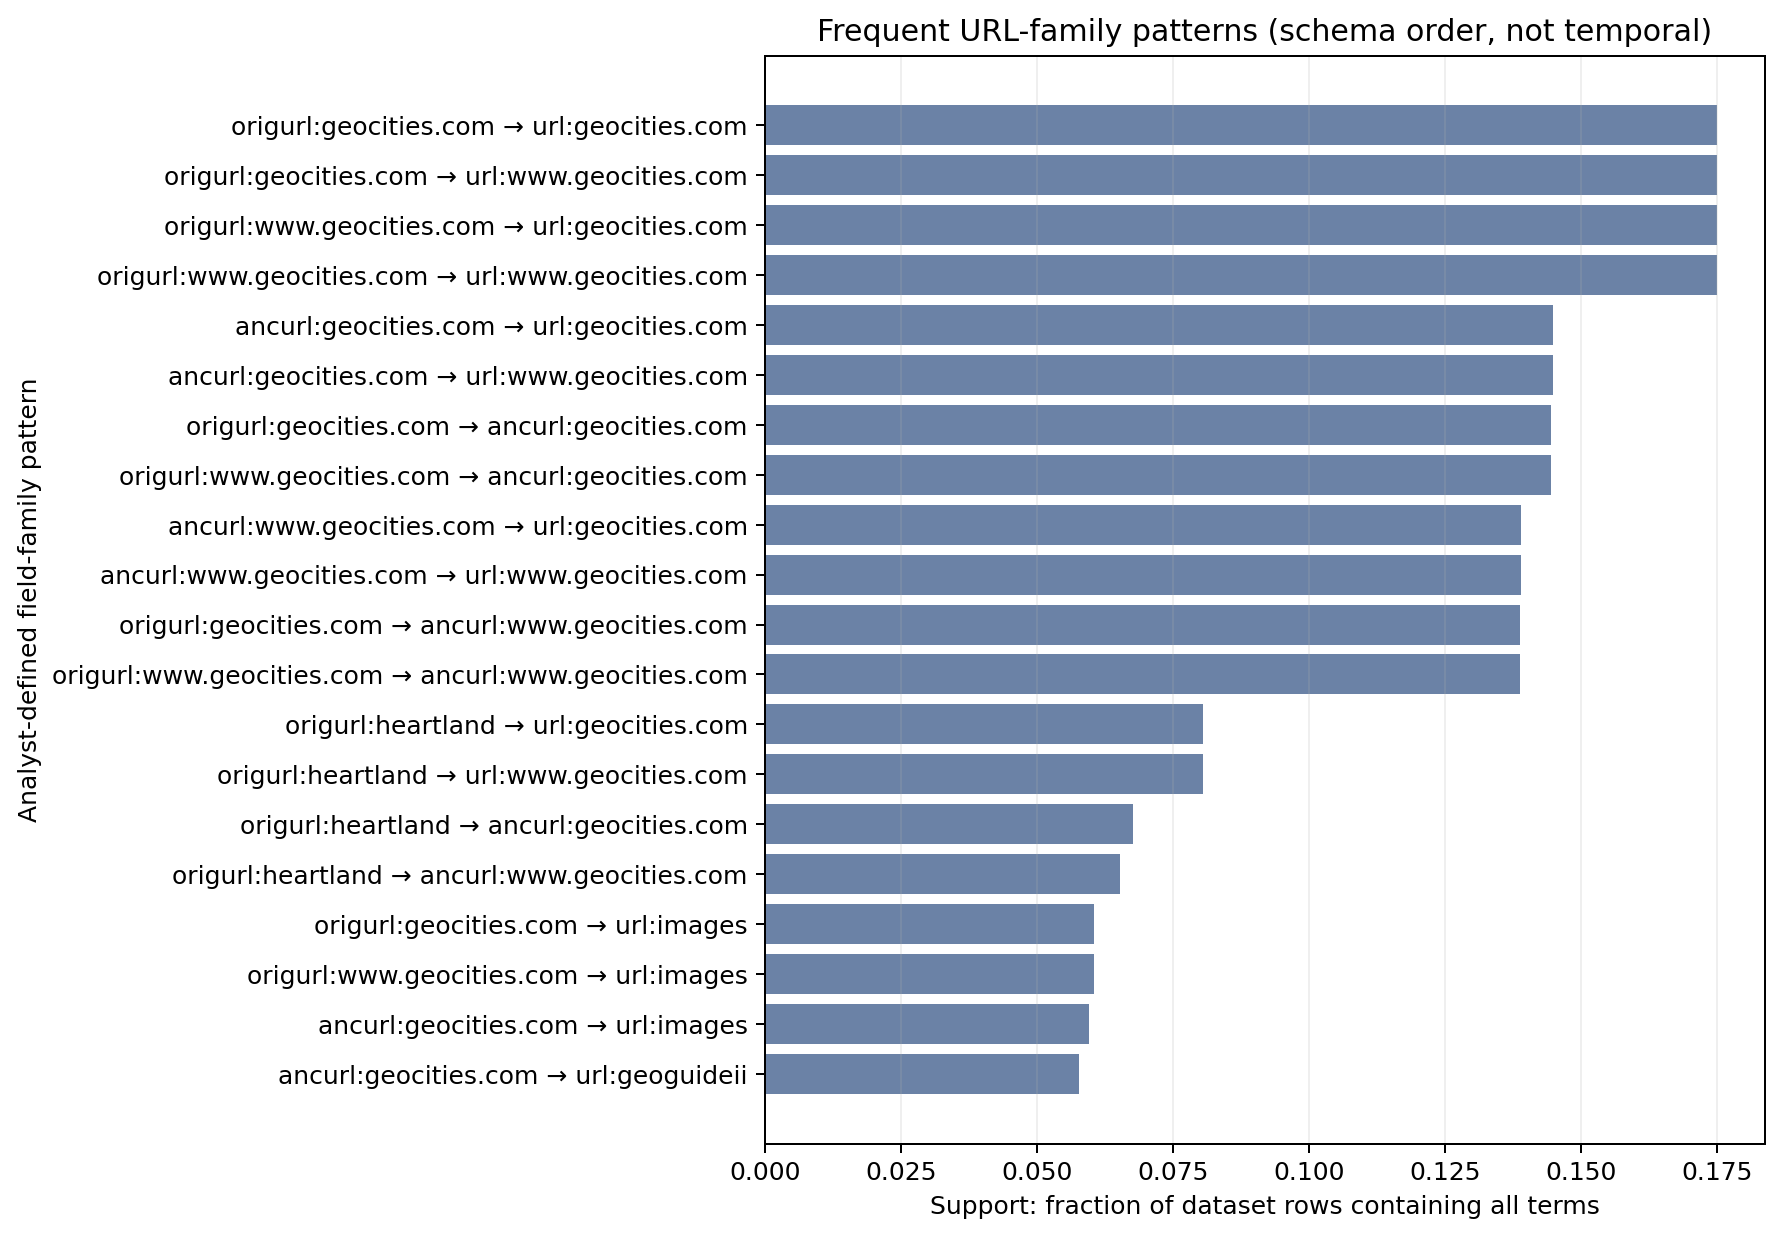

In [16]:
SEQUENCE_DIR = WORK_DIR / "artifacts" / "association"
sequence_metadata = json.loads((SEQUENCE_DIR / "schema_role_sequence_metadata.json").read_text())
sequence_patterns = pd.read_csv(SEQUENCE_DIR / "schema_role_sequential_patterns.csv")
sequence_rules = pd.read_csv(SEQUENCE_DIR / "schema_role_sequential_rules.csv")
print(f"Rows represented: {sequence_metadata['sequence_count']:,}; selected items: {sequence_metadata['selected_item_count']}; frequent patterns: {sequence_metadata['frequent_pattern_count']}; prefix-extension rules: {sequence_metadata['prefix_extension_rule_count']}.")
print("Order:", " → ".join(sequence_metadata["source_role_order"]))
print("Temporal sequence requirement fulfilled:", sequence_metadata["temporal_sequence_requirement_fulfilled"])
display(sequence_rules.sort_values(["confidence", "lift"], ascending=False).head(10))
display(Image(filename=str(SEQUENCE_DIR / "schema_role_patterns_top20.png")))

### 10.3 Repeated group-aware cross-validation

To check the single holdout result, the Decision Tree was evaluated with 5-fold `GroupKFold` over three repeats. Identical input signatures stay in one fold, and each fold fits imputation on its training partition only. These results supplement rather than replace the original holdout.

In [17]:
CV_DIR = WORK_DIR / "artifacts" / "models" / "grouped_cv"
cv_summary = json.loads((CV_DIR / "grouped_cv_metrics.json").read_text())
cv_rows = []
for metric in ["accuracy", "balanced_accuracy", "precision_ad", "recall_ad", "f1_ad", "roc_auc"]:
    result = cv_summary["aggregated_metrics"][metric]
    cv_rows.append({"Metric": metric, "Mean": result["mean"], "SD": result["std"], "Min": result["min"], "Max": result["max"]})
print(f"{cv_summary['method']}; {cv_summary['total_folds_evaluated']} folds; {cv_summary['dataset_rows']:,} rows; {cv_summary['unique_signature_groups']:,} unique signature groups.")
print("Leakage checks:", cv_summary["group_leakage_check"], ";", cv_summary["imputation_leakage_check"])
display(pd.DataFrame(cv_rows).set_index("Metric"))

5-fold GroupKFold × 3 repeats; 15 folds; 3,279 rows; 2,420 unique signature groups.
Leakage checks: verified zero overlap in every fold ; imputer fit on training fold only in every fold


,Mean,SD,Min,Max
Metric,,,,
accuracy,0.932808,0.012786,0.911585,0.952672
balanced_accuracy,0.879615,0.032439,0.788998,0.919361
precision_ad,0.737720,0.077494,0.626263,0.862069
recall_ad,0.805675,0.064603,0.623529,0.876289
f1_ad,0.767572,0.056194,0.646341,0.837438
roc_auc,0.900189,0.025592,0.854373,0.944654


### 10.4 Synthetic PySpark scale sweep

This single-machine stress test repeats rows from the existing training partition; it does not add independent examples or new Internet Ads observations. One timing was recorded per size, so this is exploratory and not a stable scaling law. The measured scope is `local[2]`, not a multi-node cluster, and Spark remained slower at every successful size. A separate 1M-row attempt failed before model fitting and has no archived timing; 2M and 4M were not tested.

Status: completed; master=local[2]; one observation per size=True; startup=1.538 s (excluded from per-size timings).


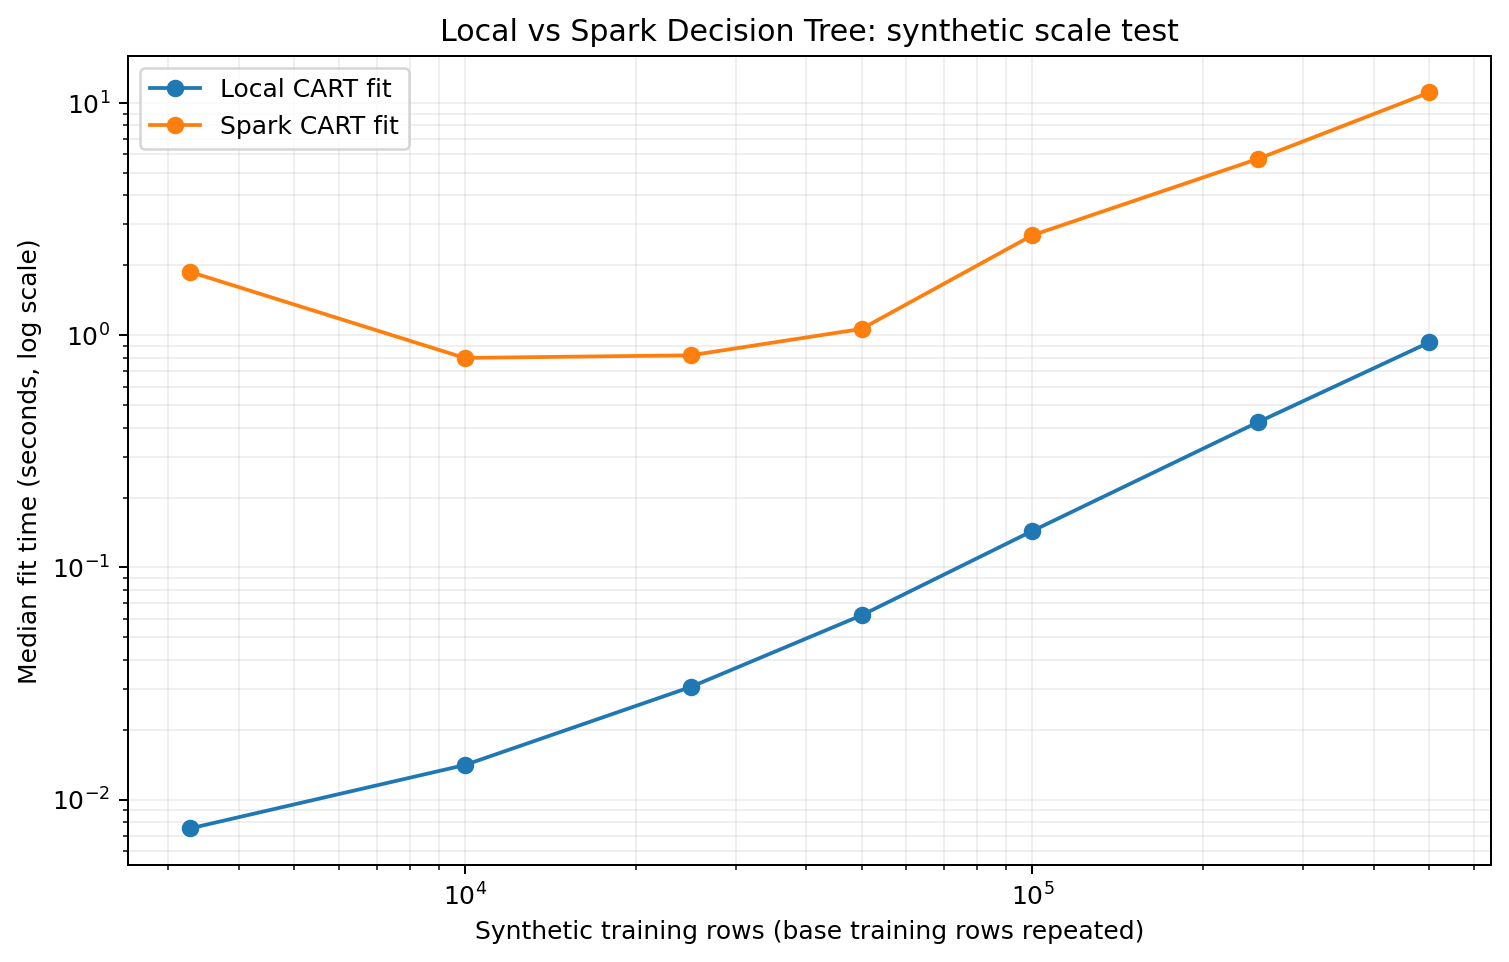

In [18]:
SCALE_DIR = WORK_DIR / "artifacts" / "spark"
scale_metadata = json.loads((SCALE_DIR / "scaled_tree_benchmark.json").read_text())
scale = pd.read_csv(SCALE_DIR / "scaled_tree_benchmark.csv")
scale_view = pd.DataFrame({
    "Rows": scale["synthetic_training_rows"],
    "Local fit (s)": scale["local_fit_seconds_median"],
    "Spark fit (s)": scale["fit_seconds_median"],
    "Spark/local fit": scale["fit_seconds_median"] / scale["local_fit_seconds_median"],
    "Local expand + fit (s)": scale["local_expand_plus_fit_seconds"],
    "Spark end-to-end (s)": scale["spark_expand_convert_materialize_fit_seconds_excluding_startup"],
    "Spark/local end-to-end": scale["spark_expand_convert_materialize_fit_seconds_excluding_startup"] / scale["local_expand_plus_fit_seconds"],
})
print(f"Status: {scale_metadata['status']}; master={scale_metadata['spark_master']}; one observation per size={scale_metadata['repeats_per_size'] == 1}; startup={scale_metadata['spark_startup_seconds_separate']:.3f} s (excluded from per-size timings).")
display(scale_view.style.format({"Local fit (s)": "{:.4f}", "Spark fit (s)": "{:.4f}", "Spark/local fit": "{:.1f}×", "Local expand + fit (s)": "{:.4f}", "Spark end-to-end (s)": "{:.4f}", "Spark/local end-to-end": "{:.1f}×"}))
display(Image(filename=str(SCALE_DIR / "scaled_tree_benchmark.png")))

## 11. MLflow tracking and reproducibility

MLflow records the run parameters, measured metrics, and output files in a local SQLite database and a local artifact directory; no tracking server is required. It is useful for keeping experiments together during this short hackathon, but it does not replace this notebook, the PDF, or the source code. The tracked runs are refreshed from the final corrected artifacts before packaging.

In [19]:
import mlflow
tracking_db = WORK_DIR / "artifacts" / "mlflow.db"
mlflow.set_tracking_uri(f"sqlite:///{tracking_db.resolve().as_posix()}")
experiment = mlflow.get_experiment_by_name("Internet Ads Hackathon (final artifacts)")
if experiment is None:
    print("No MLflow experiment found yet. Run `python3 log_experiments.py` after the final analysis outputs are generated.")
else:
    mlflow_runs = mlflow.search_runs([experiment.experiment_id], output_format="pandas")
    mlflow_runs = mlflow_runs.sort_values("start_time", ascending=False).head(4)
    cols = [c for c in ["tags.mlflow.runName", "run_id", "status", "metrics.accuracy", "metrics.ad_f1", "metrics.local_apriori_seconds", "metrics.spark_tree_fit_seconds_median", "metrics.spark_startup_seconds", "metrics.spark_tasks_completed"] if c in mlflow_runs.columns]
    print(f"Experiment: {experiment.name}; ID={experiment.experiment_id}; local database={tracking_db}")
    display(mlflow_runs[cols])

Experiment: Internet Ads Hackathon (final artifacts); ID=2; local database=/home/arpit/7th Sem/bigData/bdHackathon/artifacts/mlflow.db


2026/11/21 15:19:02 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/21 15:19:02 INFO mlflow.store.db.utils: Updating database tables
INFO  [alembic.runtime.migration] Context impl SQLiteImpl.
INFO  [alembic.runtime.migration] Will assume non-transactional DDL.
INFO  [alembic.runtime.migration] Context impl SQLiteImpl.
INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


,tags.mlflow.runName,run_id,status,metrics.accuracy,metrics.ad_f1,metrics.local_apriori_seconds,metrics.spark_tree_fit_seconds_median,metrics.spark_startup_seconds,metrics.spark_tasks_completed
0,Matched PySpark benchmarks,26edb63aa6b84dcc84adcc01d8654485,FINISHED,NaN,NaN,0.037974,0.865233,1.525296,1.0
1,DBSCAN geometry clustering,452a0bdf798c4867b98058bacf58f739,FINISHED,NaN,NaN,NaN,NaN,NaN,NaN
2,Grouped holdout Decision Tree,bef48765e56e4221894f7ea4729df7bd,FINISHED,0.919207,0.743961,NaN,NaN,NaN,NaN
3,Apriori and CHARM,f37242ed001c46b8a2d8f5b688f7f0bd,FINISHED,NaN,NaN,NaN,NaN,NaN,NaN


## 12. Numbered visualization index and individual inferences

The assignment handout asks for at least ten distinct plots with an inference for each. The 20 numbered report figures include the seven Lecture 4 forms (bar, pie, histogram, dot, stem-and-leaf, scatter, box), a Decision Tree diagram and ROC curve from classification material, and a supplementary geometry-only dendrogram from the clustering slides. A local-versus-Spark runtime chart and the other remaining figures are separately labeled diagnostics. Every caption below is computed from the source or saved analysis output.

The dendrogram is a fixed-seed, 120-row geometry-only illustration of a course plot. It is separate from DBSCAN and does not define the reported DBSCAN clusters.

### Figure 1 — bar chart

The raw file contains 2,820 nonads and 459 ads, a 6.14:1 imbalance. Class-aware metrics are therefore needed alongside accuracy.

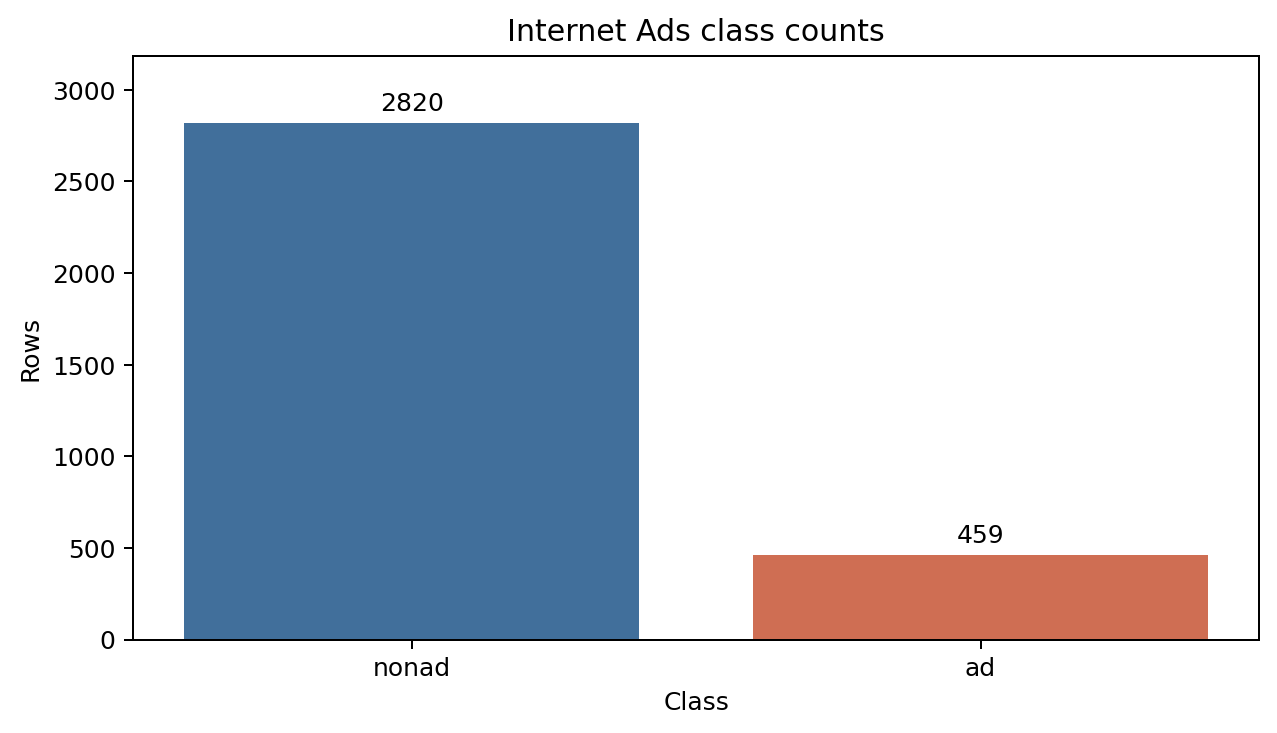

In [20]:
from IPython.display import Image, display
display(Image(filename=str(WORK_DIR / 'artifacts/report/figures/01_class_counts.png')))

### Figure 2 — pie chart

Ads account for 14.0% of the 3,279 rows, so a majority-only classifier would hide poor ad detection.

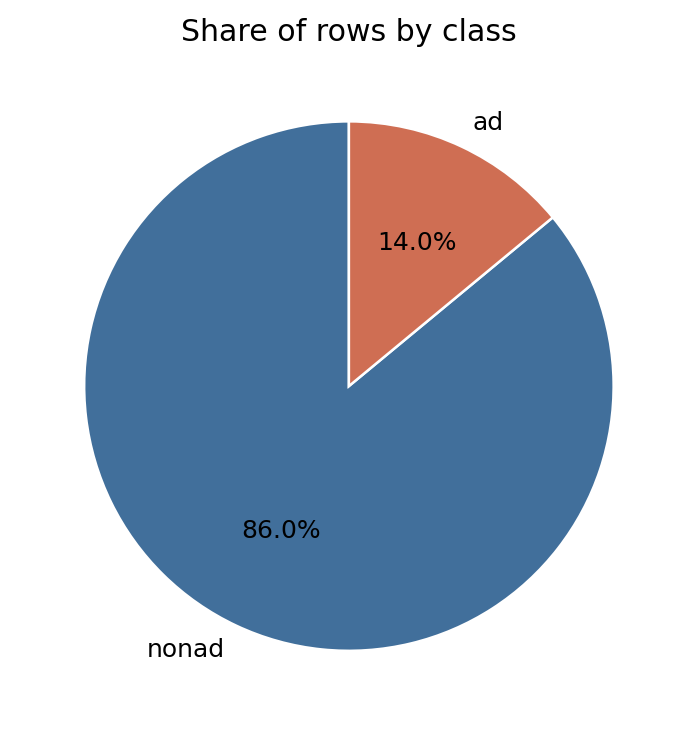

In [21]:
from IPython.display import Image, display
display(Image(filename=str(WORK_DIR / 'artifacts/report/figures/02_class_share.png')))

### Figure 3 — lollipop chart

Geometry is partly unknown in 910 rows; the separate local indicator is missing in 15 rows. Missing values were kept distinct from observed zeroes.

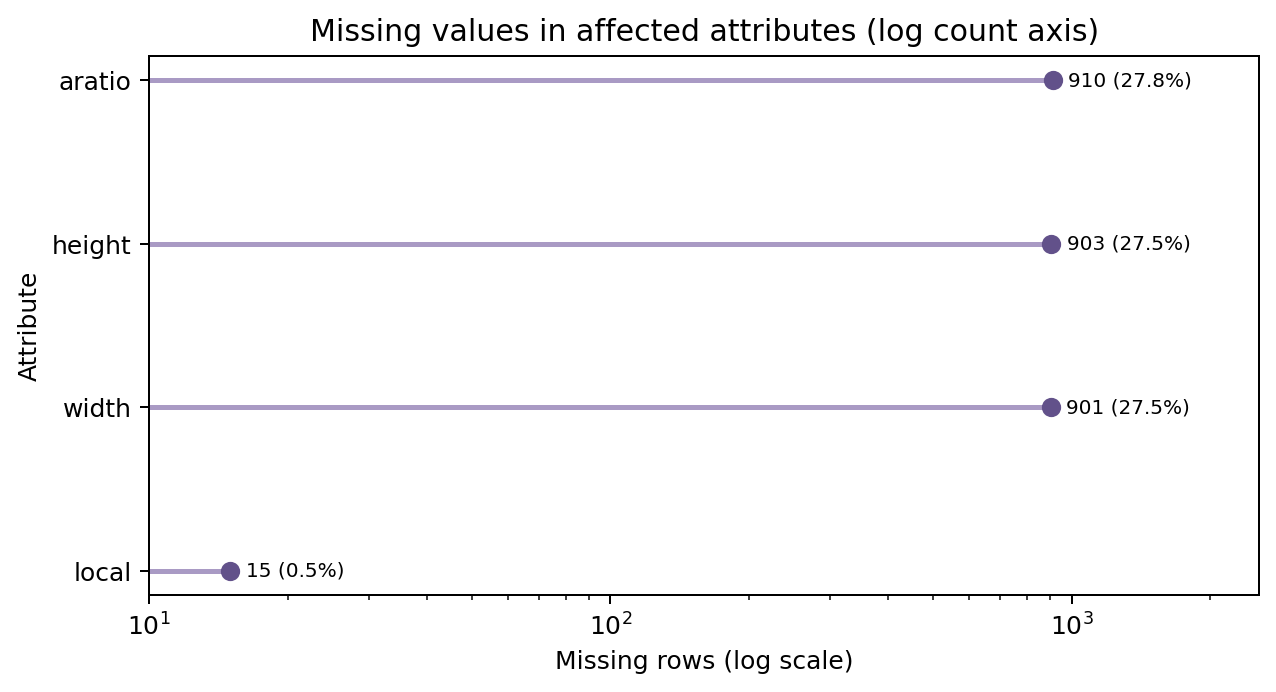

In [22]:
from IPython.display import Image, display
display(Image(filename=str(WORK_DIR / 'artifacts/report/figures/03_missingness_lollipop.png')))

### Figure 4 — histogram

The log1p axes make the long upper tails visible without removing large measurements. Raw skewness is height 2.47, width 1.63, aratio 7.03; the transform is only for display, and raw values remain in the saved cleaned copy.

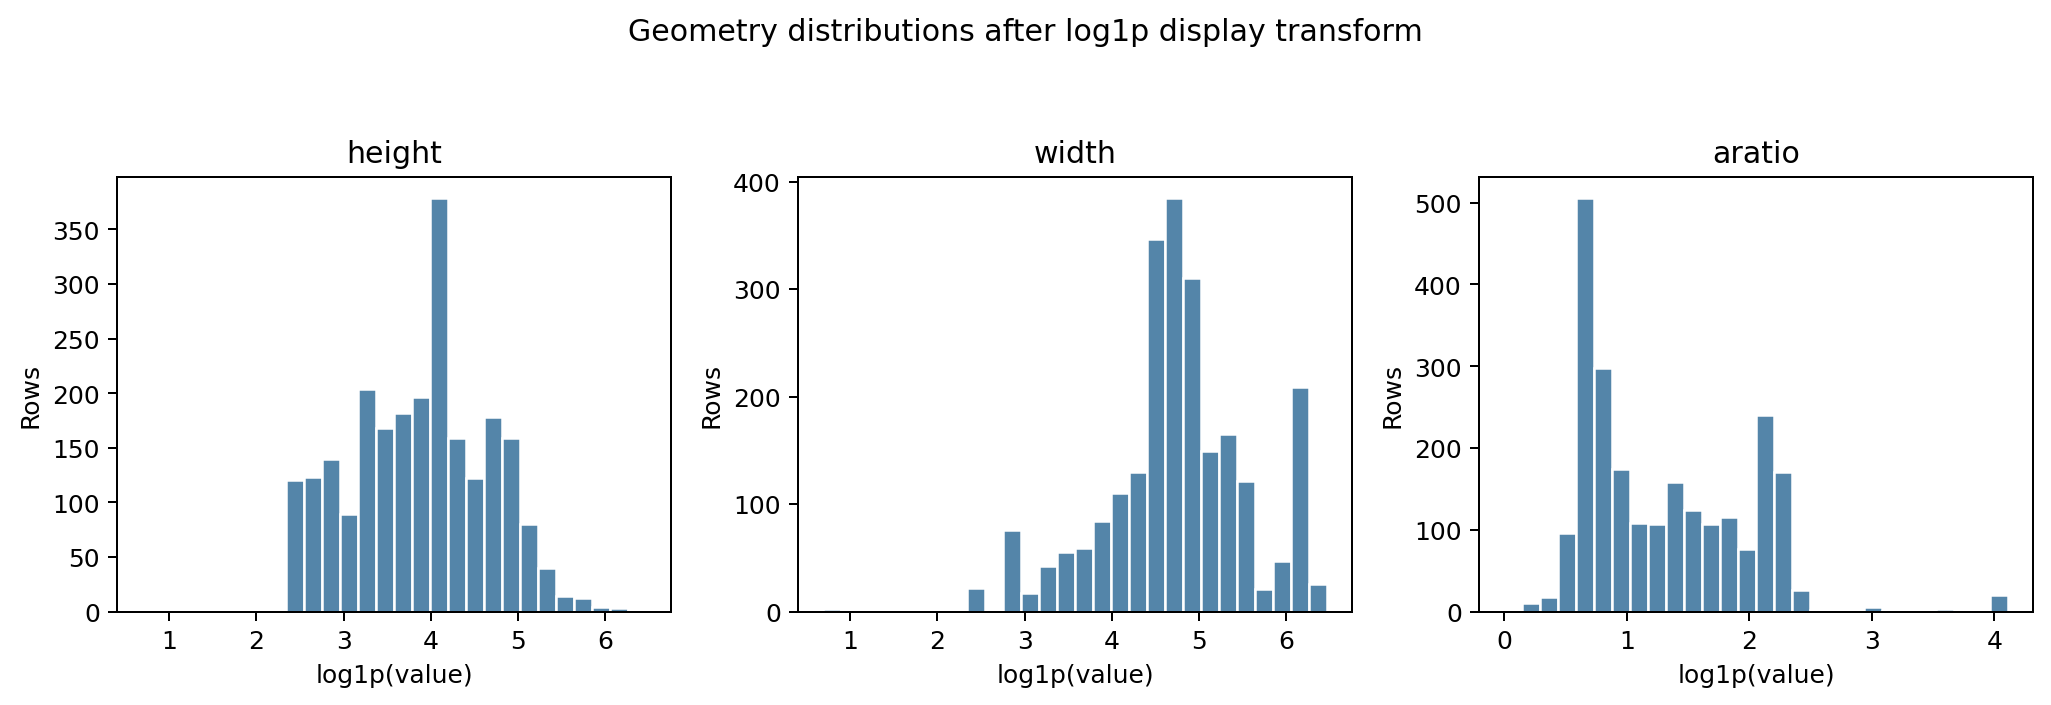

In [23]:
from IPython.display import Image, display
display(Image(filename=str(WORK_DIR / 'artifacts/report/figures/04_geometry_histograms.png')))

### Figure 5 — box plot

Observed medians (ad / nonad) are height: ad 60, nonad 43, width: ad 460, nonad 101, aratio: ad 7.8, nonad 1.7241. These descriptive differences overlap and do not by themselves define a classifier.

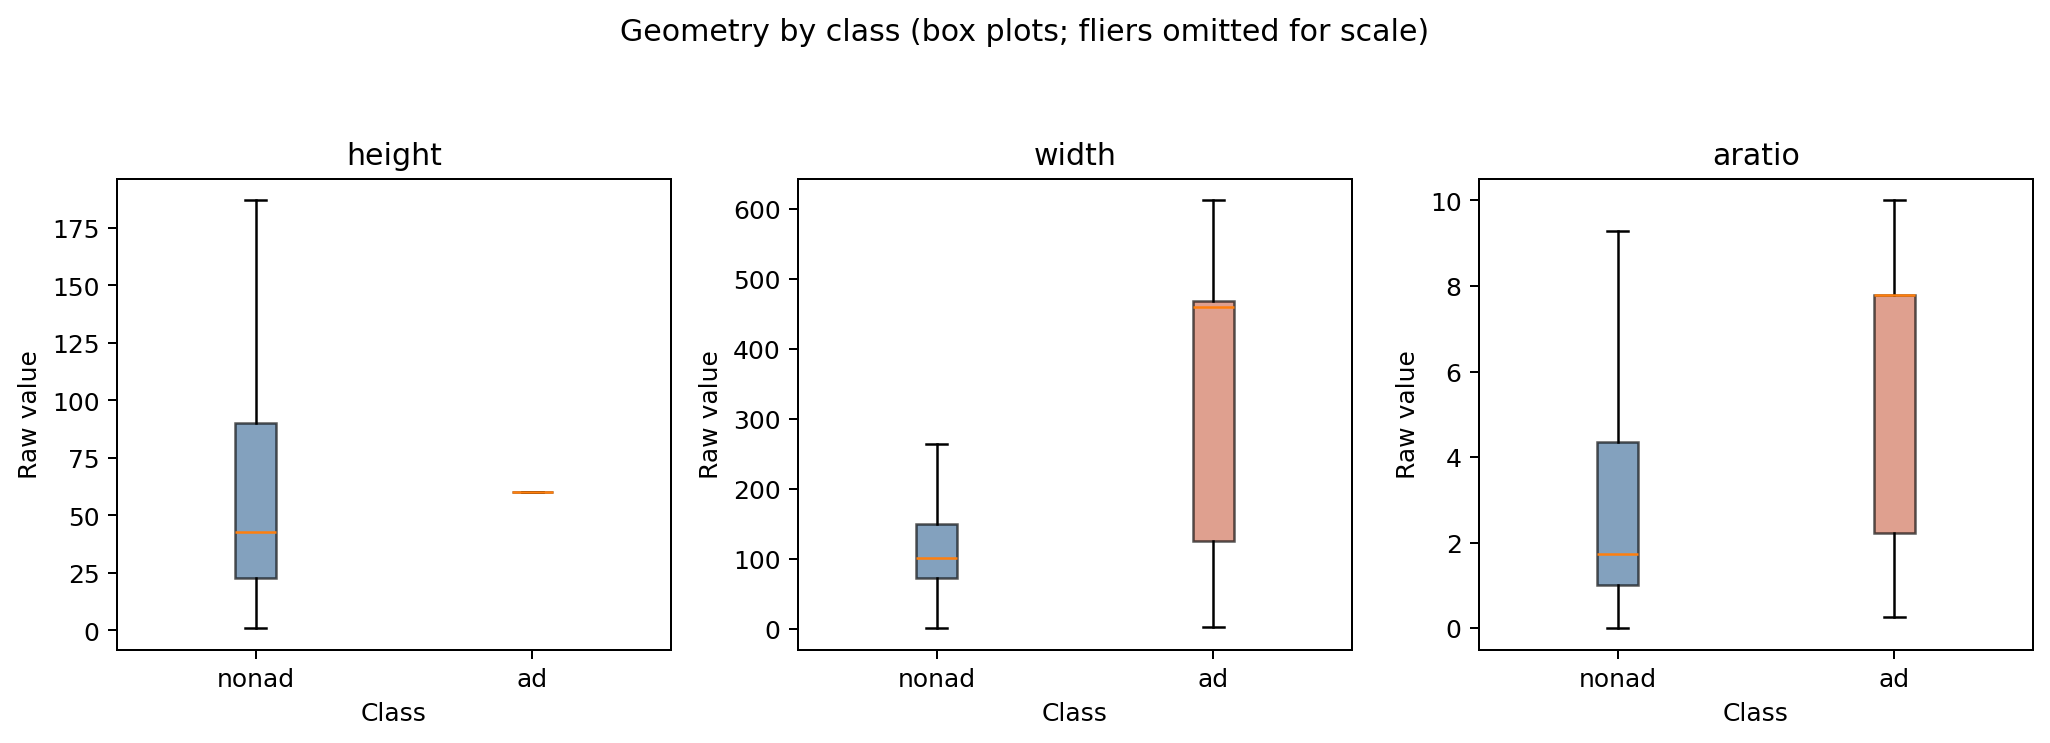

In [24]:
from IPython.display import Image, display
display(Image(filename=str(WORK_DIR / 'artifacts/report/figures/05_geometry_boxplots.png')))

### Figure 6 — scatter plot

For rows with both dimensions, Spearman width-height correlation is 0.411. The cloud shows substantial geometric spread; the plot is descriptive, not evidence of causation.

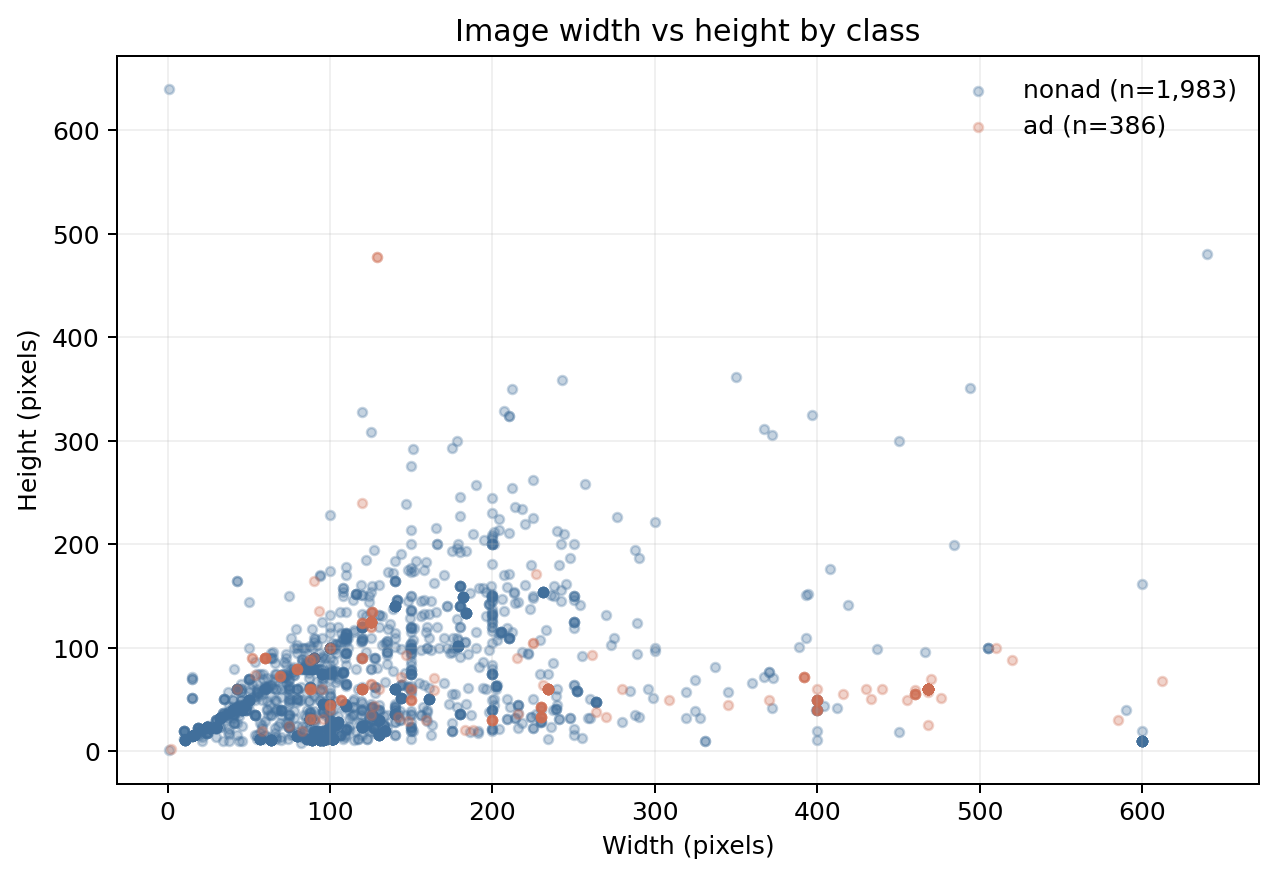

In [25]:
from IPython.display import Image, display
display(Image(filename=str(WORK_DIR / 'artifacts/report/figures/06_width_height_scatter.png')))

### Figure 7 — dot plot

The three most prevalent observed indicators are local 76.4%, url*images 28.8%, origurl*www.geocities.com 18.5%. This descriptive ranking motivated a support-filtered transaction alphabet; it is not a model feature-importance ranking.

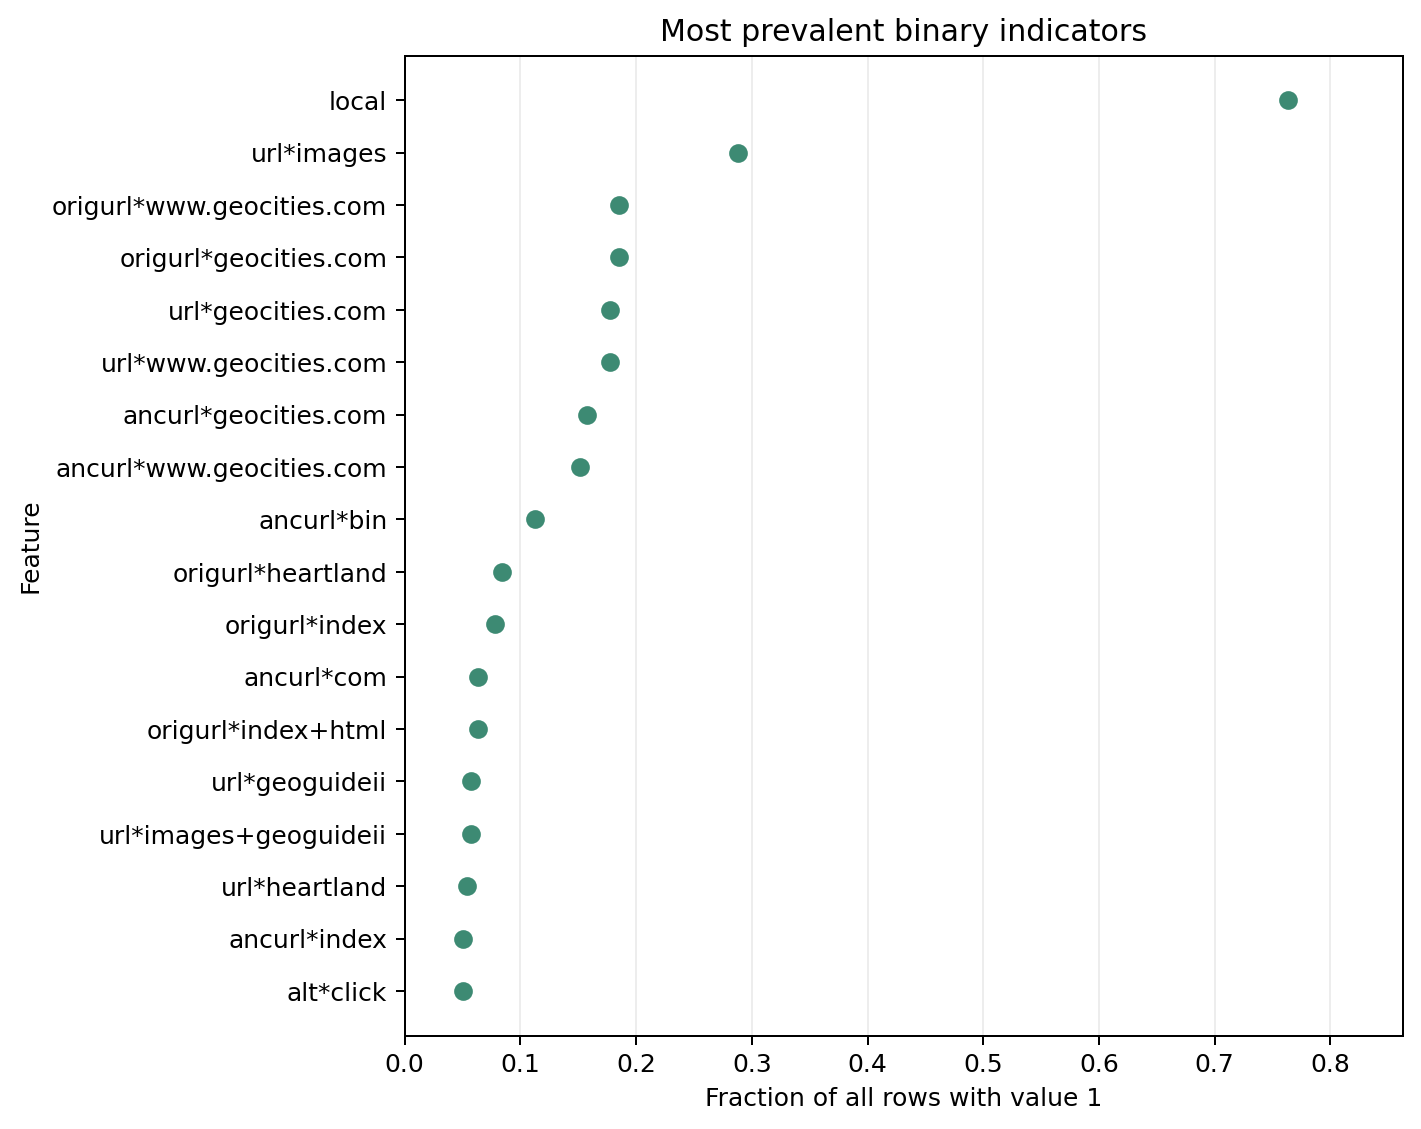

In [26]:
from IPython.display import Image, display
display(Image(filename=str(WORK_DIR / 'artifacts/report/figures/07_binary_prevalence_dot.png')))

### Figure 8 — correlation heatmap

Spearman correlations are height/width 0.41; height/aratio -0.51; width/aratio 0.49. Correlation describes monotonic association, not causation; missing pairs are omitted.

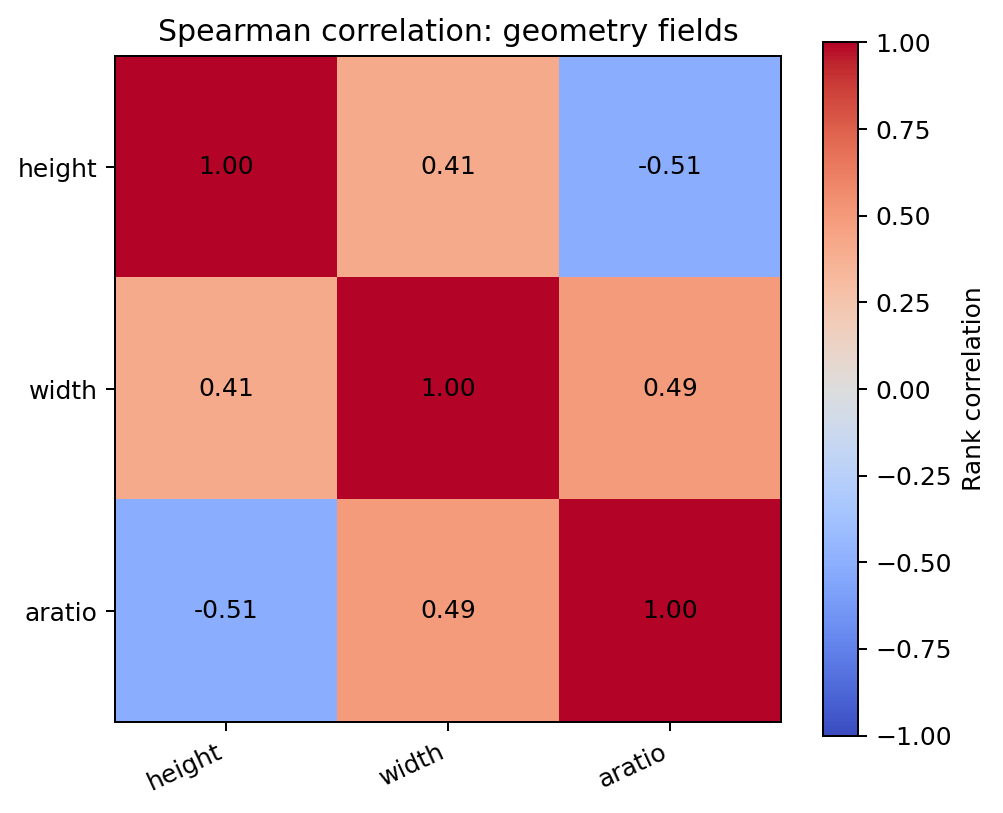

In [27]:
from IPython.display import Image, display
display(Image(filename=str(WORK_DIR / 'artifacts/report/figures/08_geometry_correlation_heatmap.png')))

### Figure 9 — stem-and-leaf display

In the fixed-seed sample of 100, heights range from 11 to 351 pixels; stem 1 (the 10s) occurs most often (19 values). It is a visualization sample only; all source rows remain in the analyses.

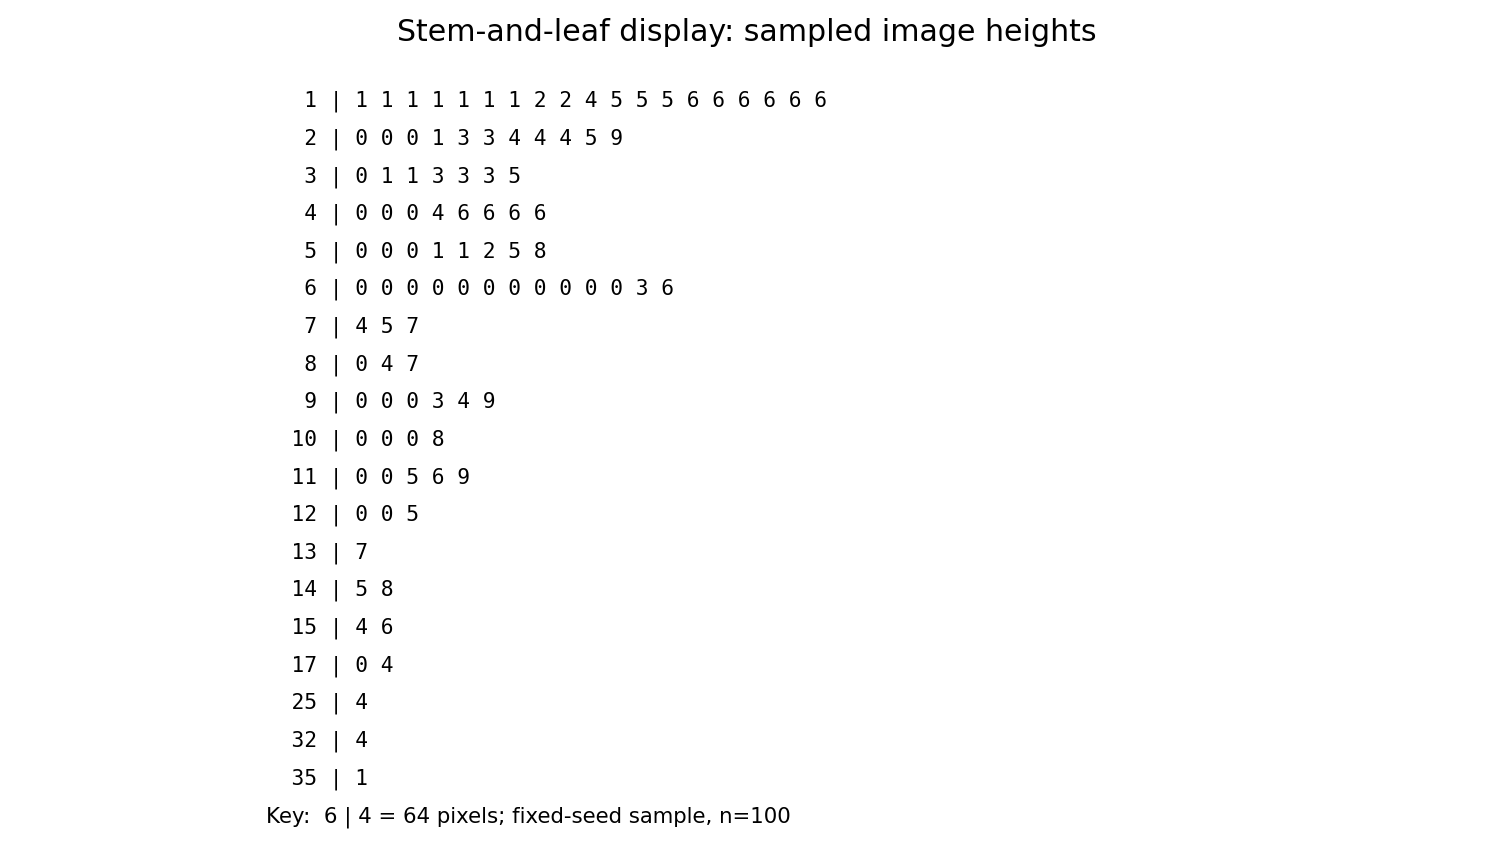

In [28]:
from IPython.display import Image, display
display(Image(filename=str(WORK_DIR / 'artifacts/report/figures/09_height_stem_leaf.png')))

### Figure 10 — violin plot

The violin shows the width distribution's shape on a log1p axis; raw median widths are 101 pixels for nonads and 460 for ads. Broad spread means median separation is not perfect classification.

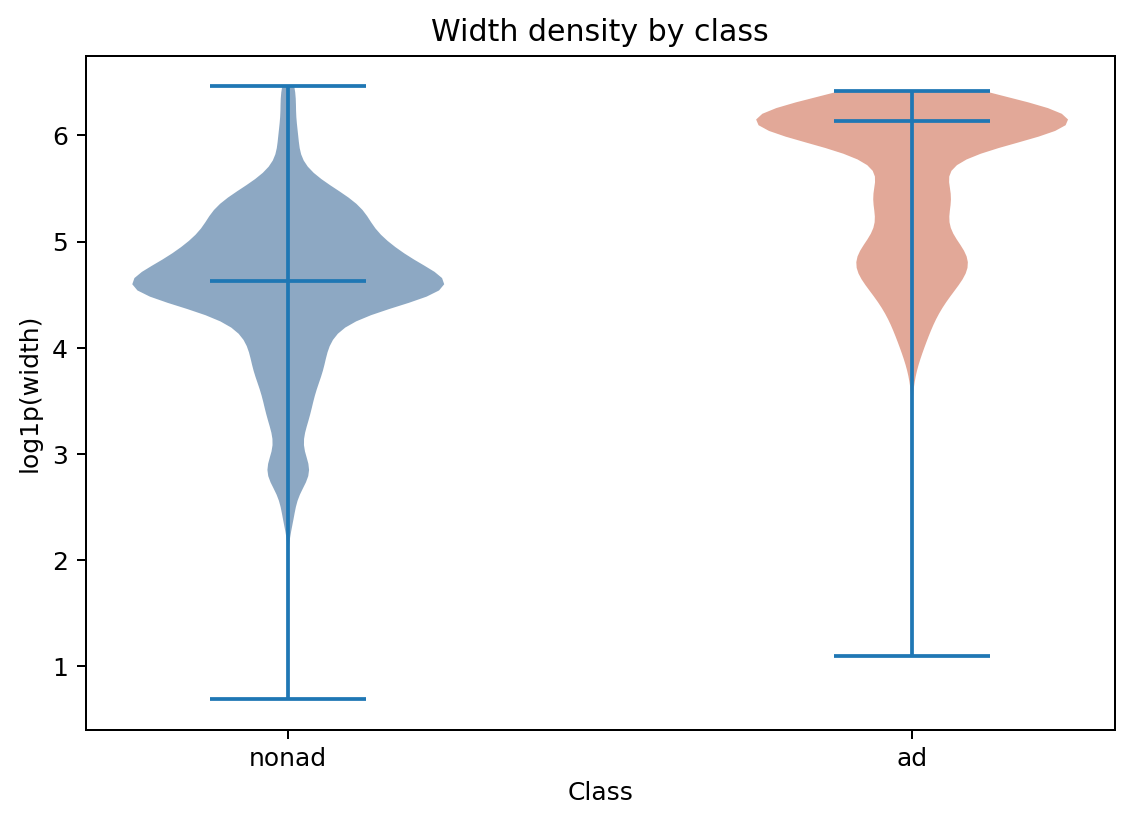

In [29]:
from IPython.display import Image, display
display(Image(filename=str(WORK_DIR / 'artifacts/report/figures/10_width_violin.png')))

### Figure 11 — empirical CDF

The CDF compares the full aspect-ratio distributions and makes class quantiles visible. The raw medians are ad 7.8 and nonad 1.7241; missing values are omitted from this plot.

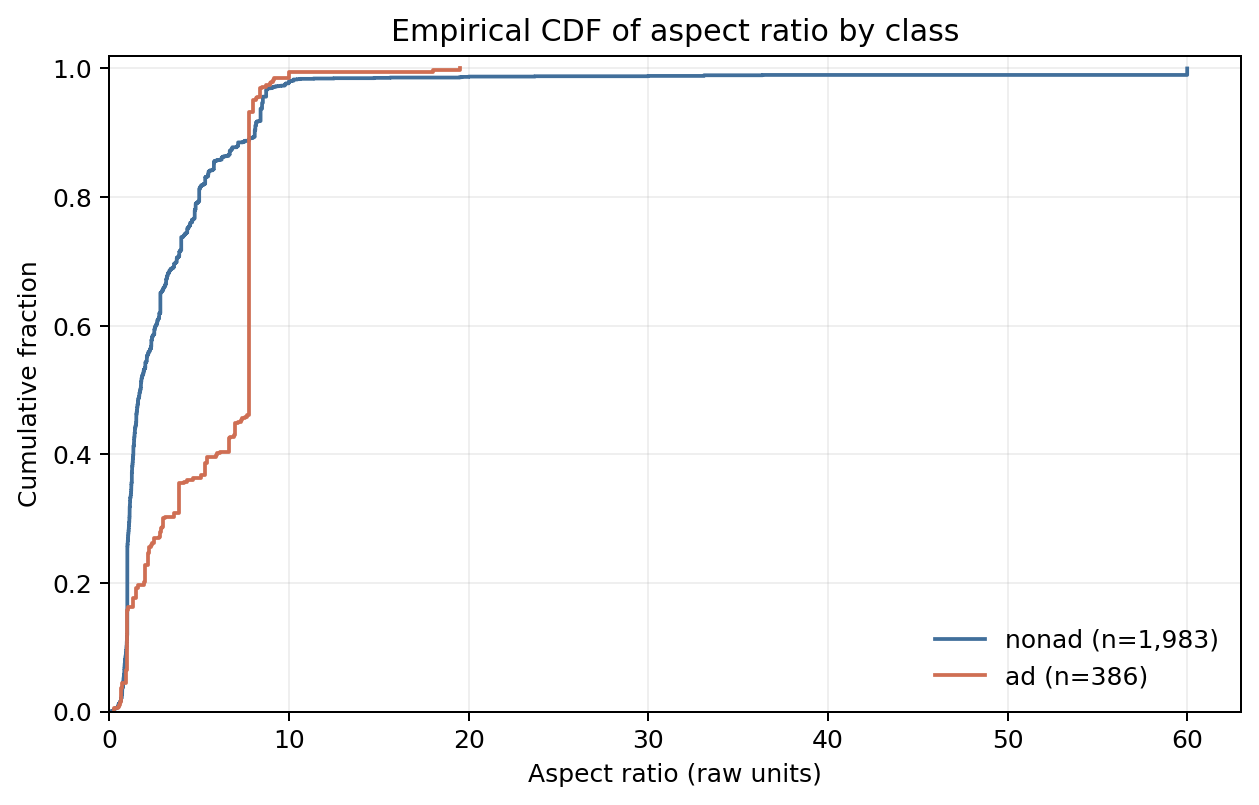

In [30]:
from IPython.display import Image, display
display(Image(filename=str(WORK_DIR / 'artifacts/report/figures/11_aratio_ecdf.png')))

### Figure 12 — bubble plot

The plot shows all 1,190 class-consequent rules; marker size reflects support count and color is lift. Many rules share the same support/confidence values. The highest-lift rule has support 0.058, confidence 0.913, and lift 6.523; association is not causation.

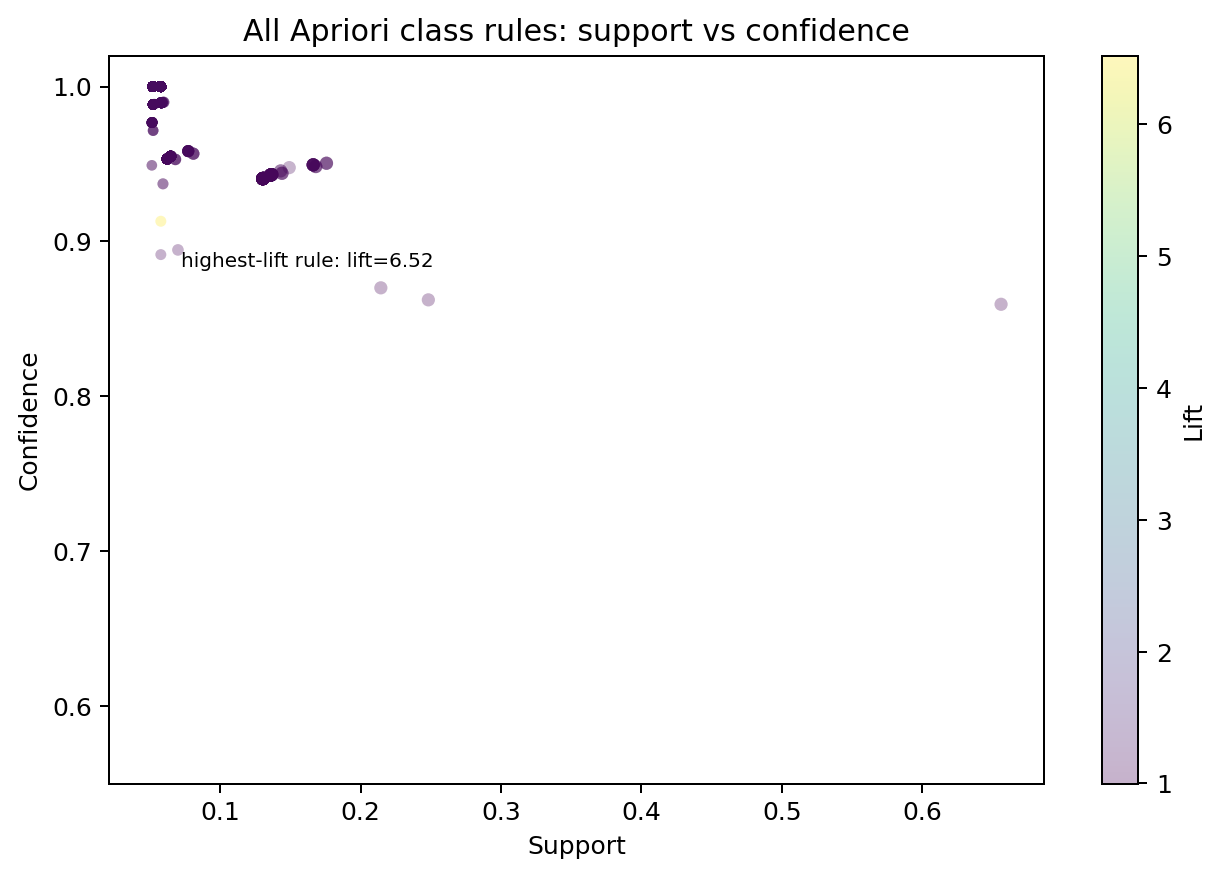

In [31]:
from IPython.display import Image, display
display(Image(filename=str(WORK_DIR / 'artifacts/report/figures/12_apriori_rules_bubble.png')))

### Figure 13 — lollipop chart

Feature-only CHARM found 41 closed itemsets at 5% support. The most common closure size is 1 items (8 closures). Closed sets are a compact representation and the output was verified against exhaustive TID intersections.

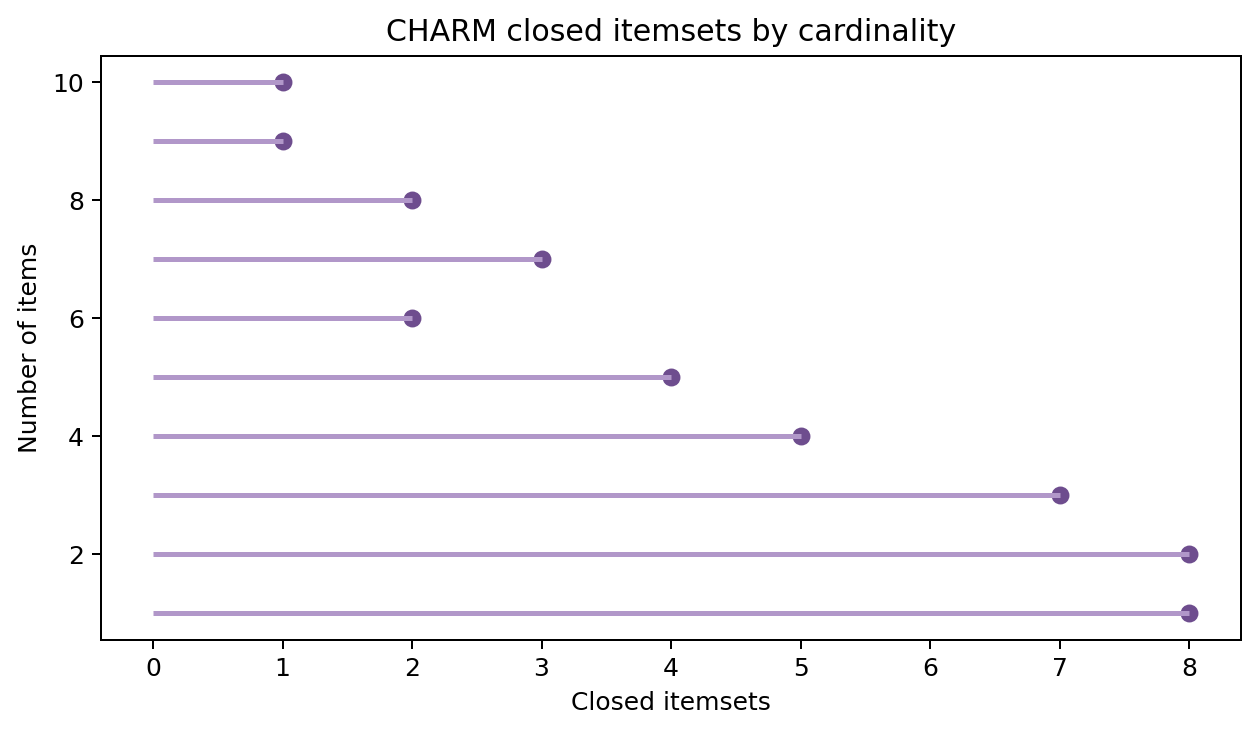

In [32]:
from IPython.display import Image, display
display(Image(filename=str(WORK_DIR / 'artifacts/report/figures/13_charm_closed_lengths.png')))

### Figure 14 — confusion matrix

On the grouped test set, the tree identifies 77 of 92 ads and misses 15; it flags 38 nonads as ads. This threshold-dependent view complements ROC-AUC.

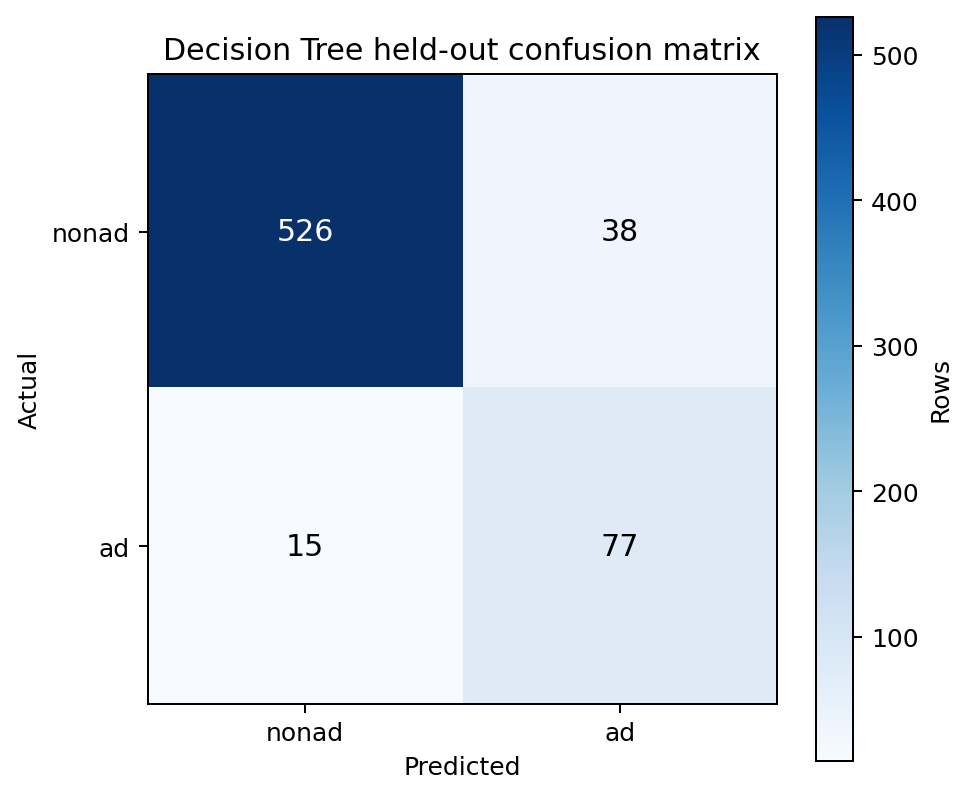

In [33]:
from IPython.display import Image, display
display(Image(filename=str(WORK_DIR / 'artifacts/report/figures/14_tree_confusion_matrix.png')))

### Figure 15 — ROC curve

The held-out ROC-AUC is 0.9116. It measures ranking over thresholds and should be read with ad precision/recall because the classes are imbalanced.

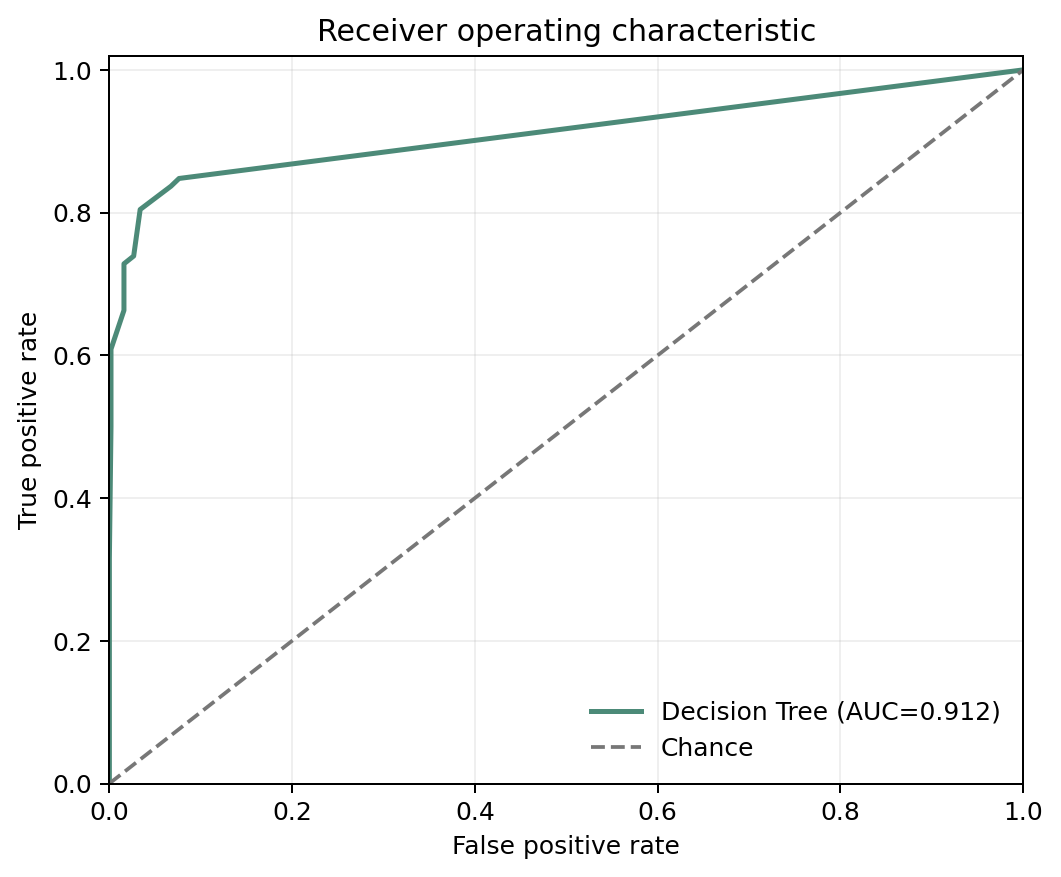

In [34]:
from IPython.display import Image, display
display(Image(filename=str(WORK_DIR / 'artifacts/report/figures/15_tree_roc_curve.png')))

### Figure 16 — decision tree diagram

The fitted depth-5 CART structure gives 12 terminal IF-THEN rules. Width, height, and URL/anchor indicators are split variables; the rule list is also provided as a separate CSV and text file.

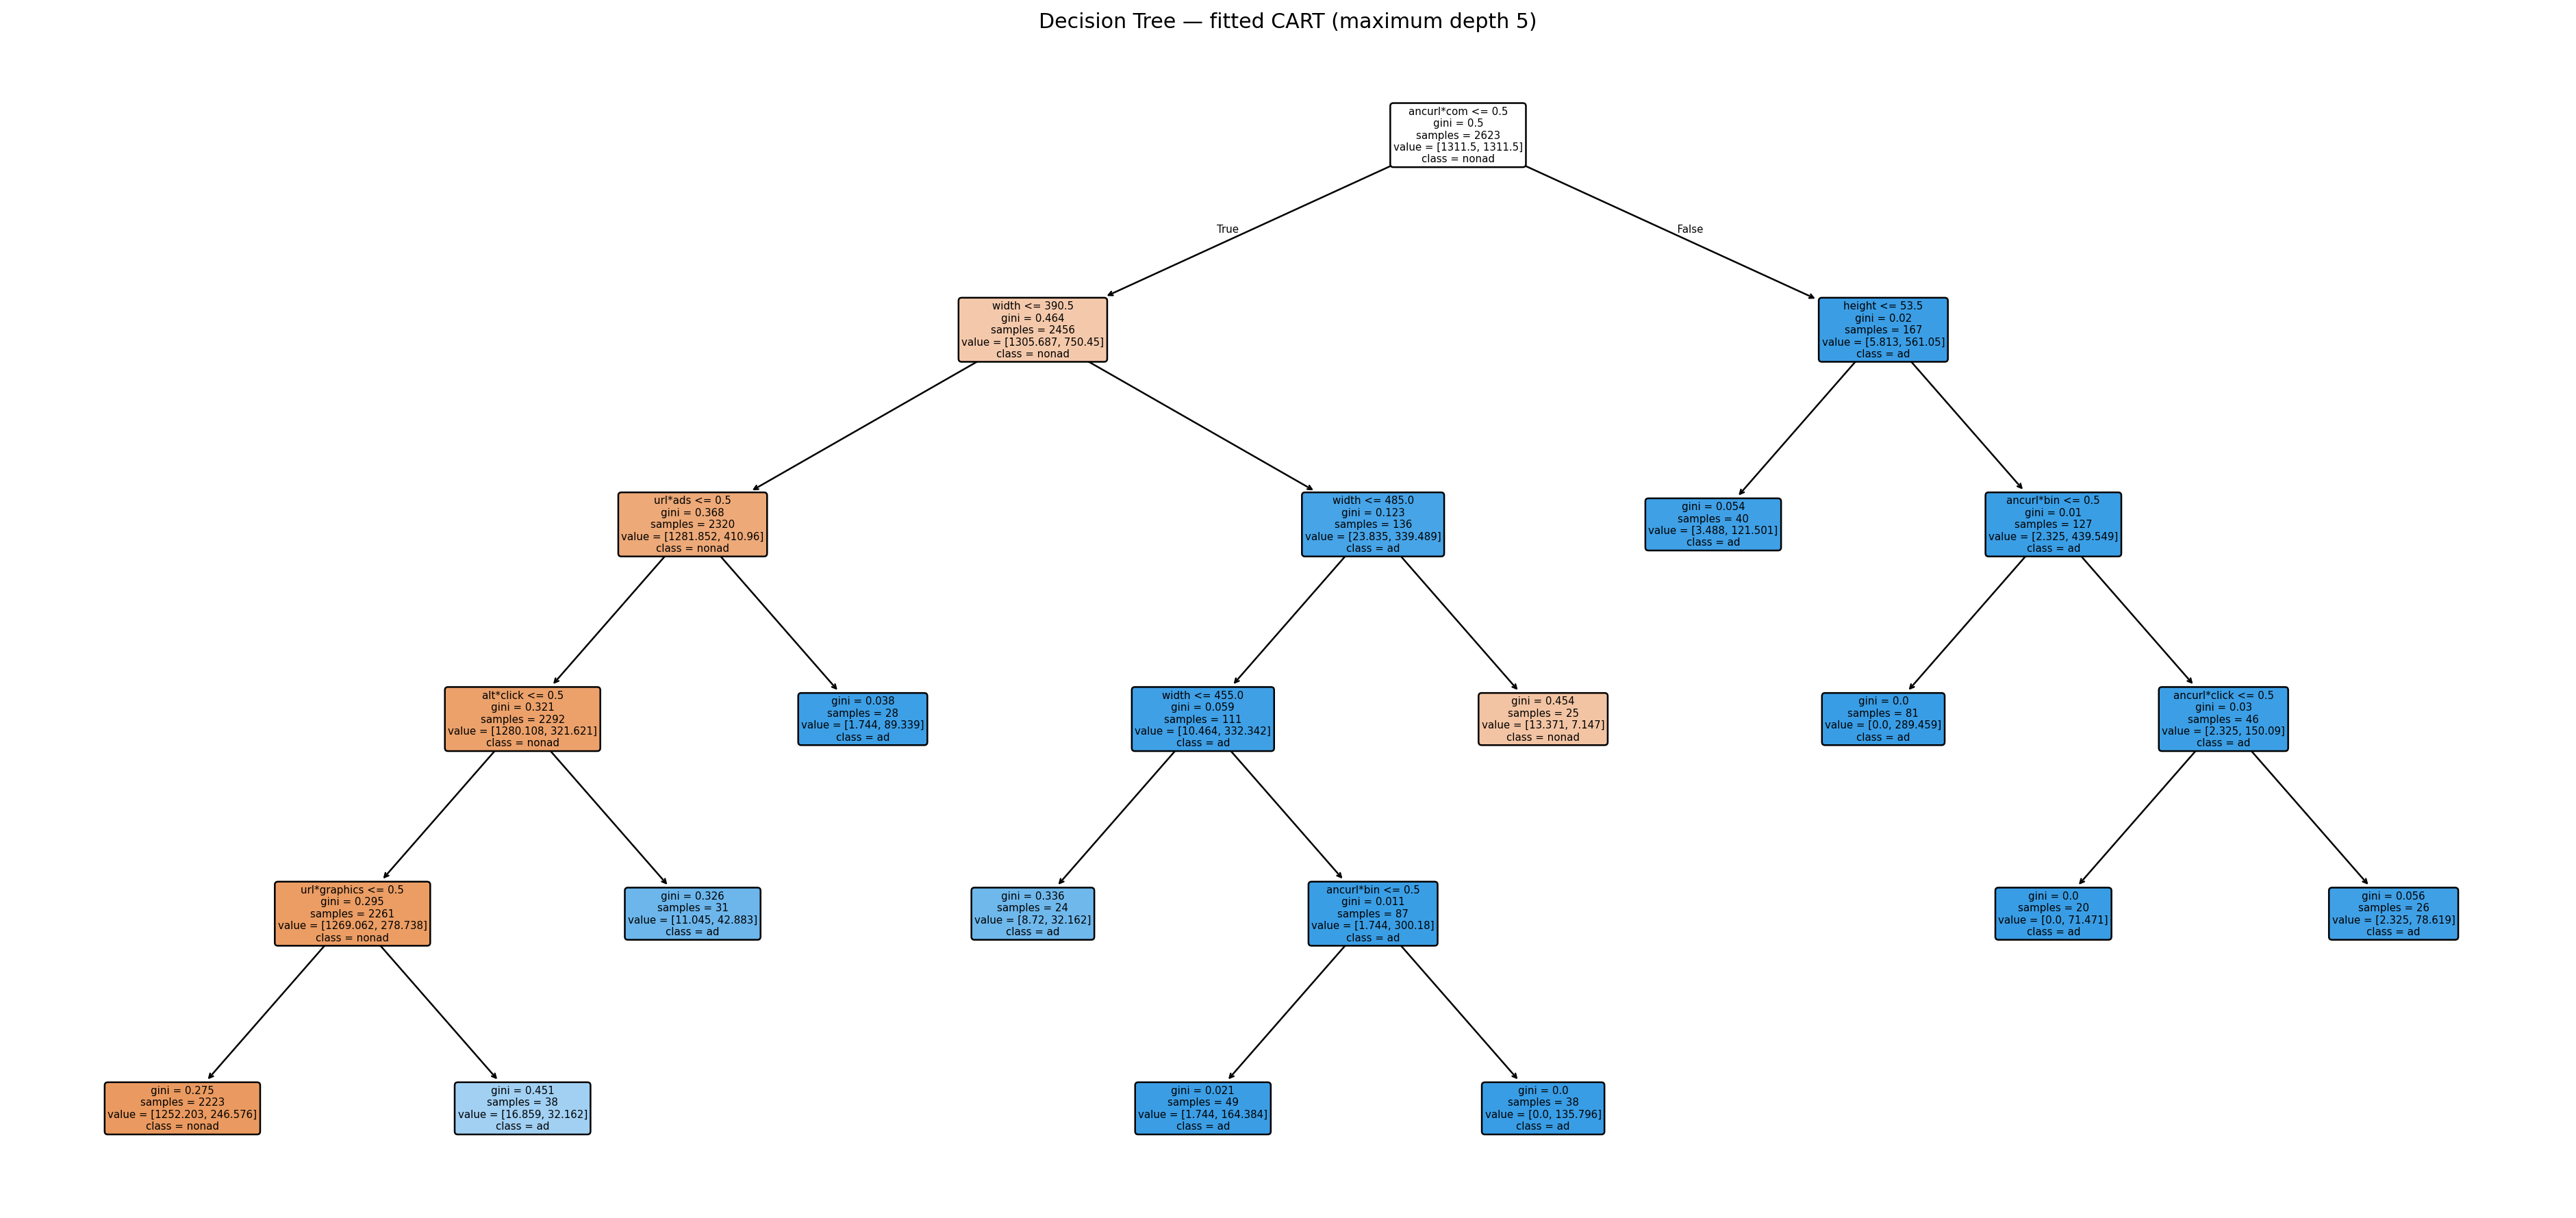

In [35]:
from IPython.display import Image, display
display(Image(filename=str(WORK_DIR / 'artifacts/report/figures/16_decision_tree_diagram.png')))

### Figure 17 — k-distance curve

The 10-neighbor distance elbow selected epsilon=0.4578. Epsilon is a heuristic from the unlabeled distance curve; the saved sensitivity sweep shows how nearby settings change noise and clusters.

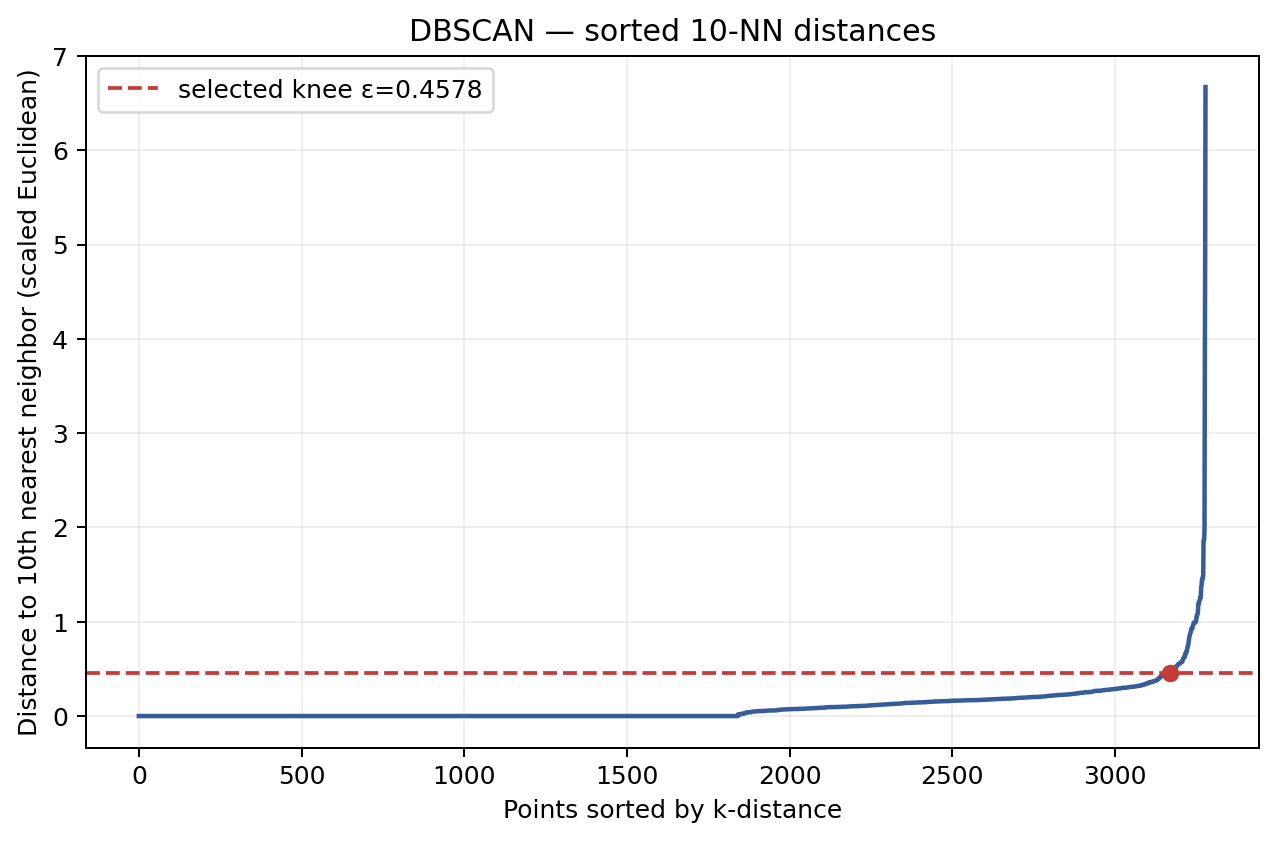

In [36]:
from IPython.display import Image, display
display(Image(filename=str(WORK_DIR / 'artifacts/report/figures/17_dbscan_k_distance.png')))

### Figure 18 — cluster projection scatter plot

The feature-only DBSCAN run found 3 clusters and 70 noise rows (2.13%). The target was excluded from distance construction and clustering; class ARI is reported only as post-hoc context.

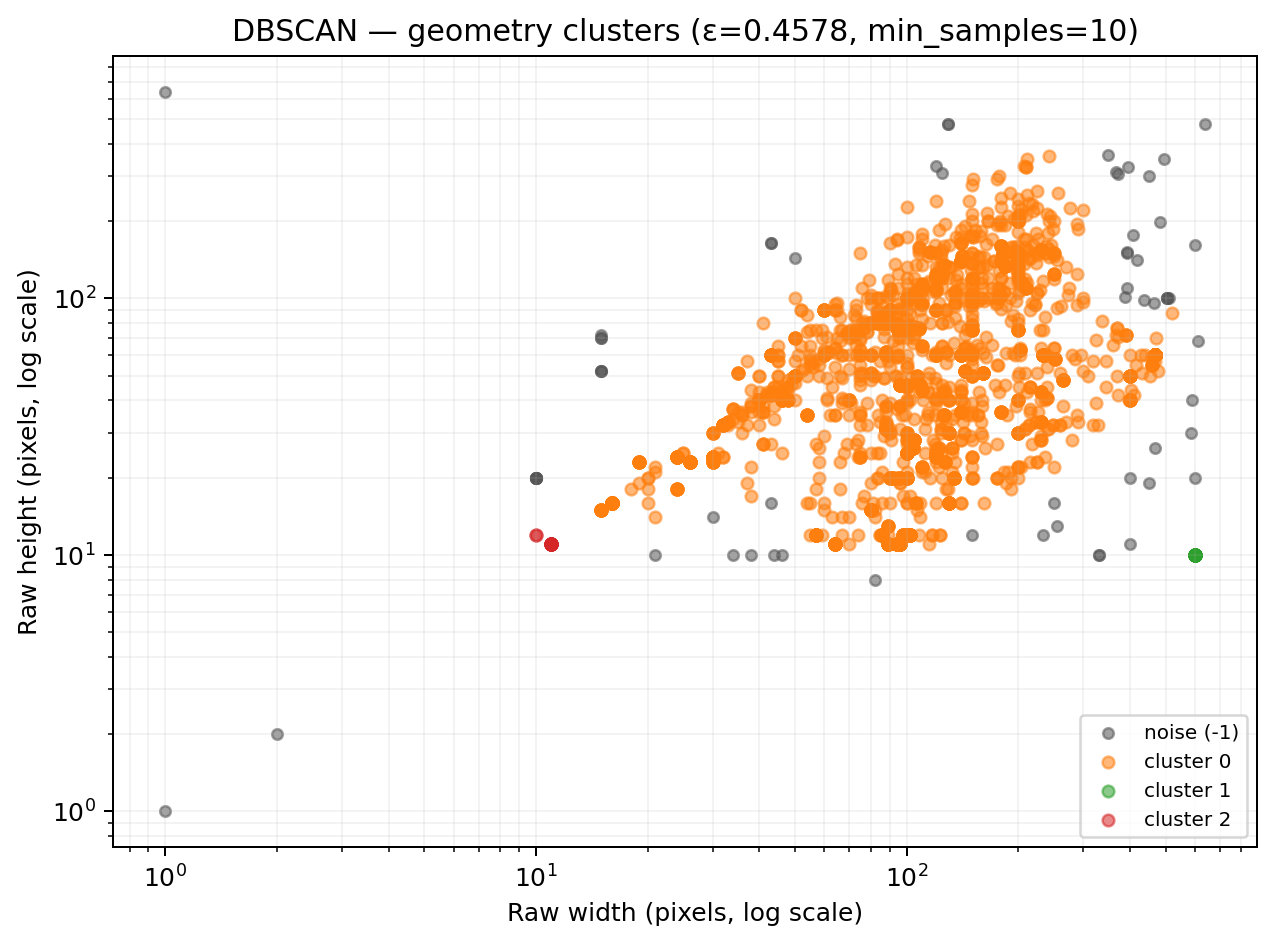

In [37]:
from IPython.display import Image, display
display(Image(filename=str(WORK_DIR / 'artifacts/report/figures/18_dbscan_clusters.png')))

### Figure 19 — log-scale grouped bar chart

Spark median fit was 28.2× local for the Decision Tree (0.8652 vs 0.0306 s) and 1.9× for FP-Growth fit vs Apriori mining (0.0712 vs 0.0380 s; algorithms differ). Including Spark conversion/materialization and prediction/collection, end-to-end task times were 5.700 s for the tree and 0.446 s for pattern mining, excluding the shared 1.525 s startup. Spark was slower on this dataset.

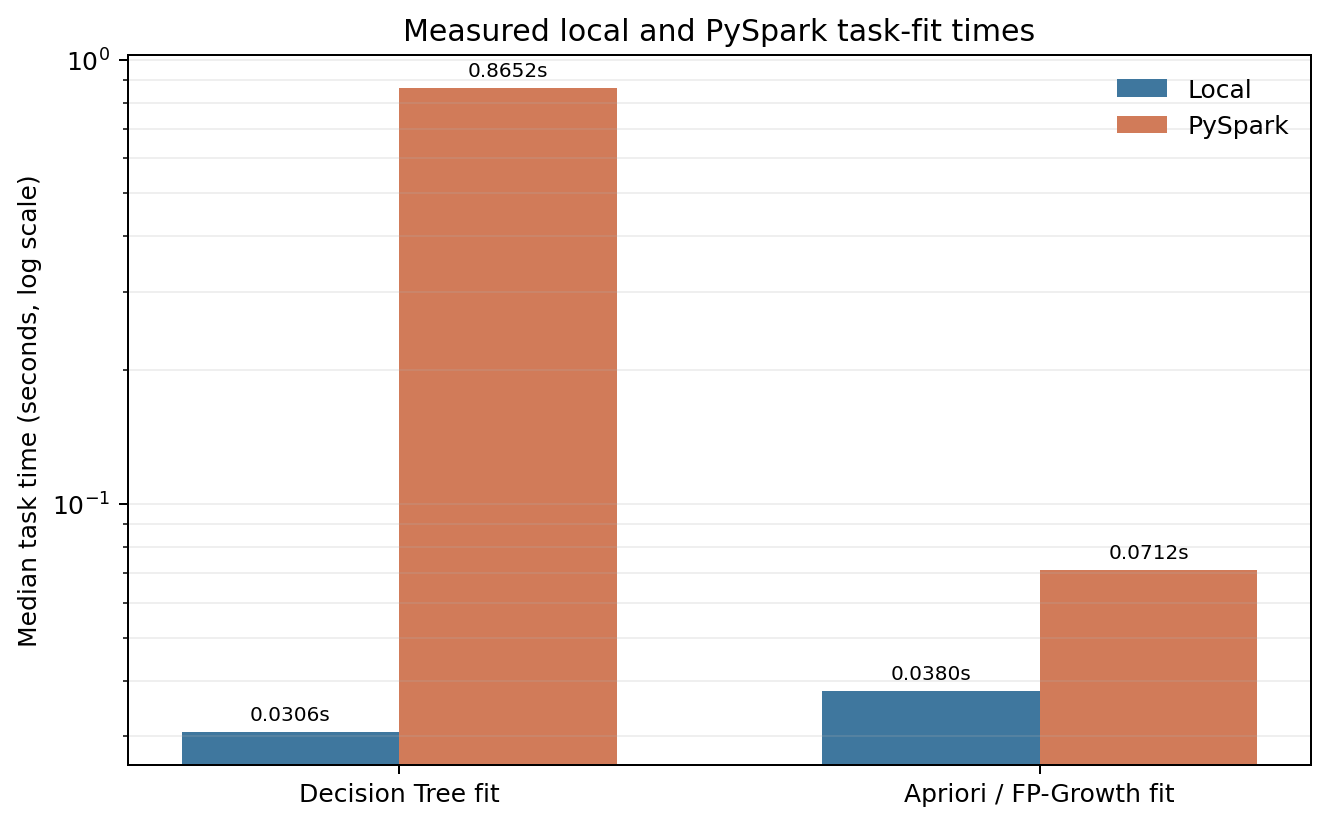

In [38]:
from IPython.display import Image, display
display(Image(filename=str(WORK_DIR / 'artifacts/report/figures/19_spark_runtime_comparison.png')))

### Figure 20 — dendrogram

For a fixed-seed sample of 120 rows, average linkage's final merge occurs at transformed distance 4.349. This course visualization uses geometry only; it is separate from DBSCAN and does not use class labels or define the reported DBSCAN clusters.

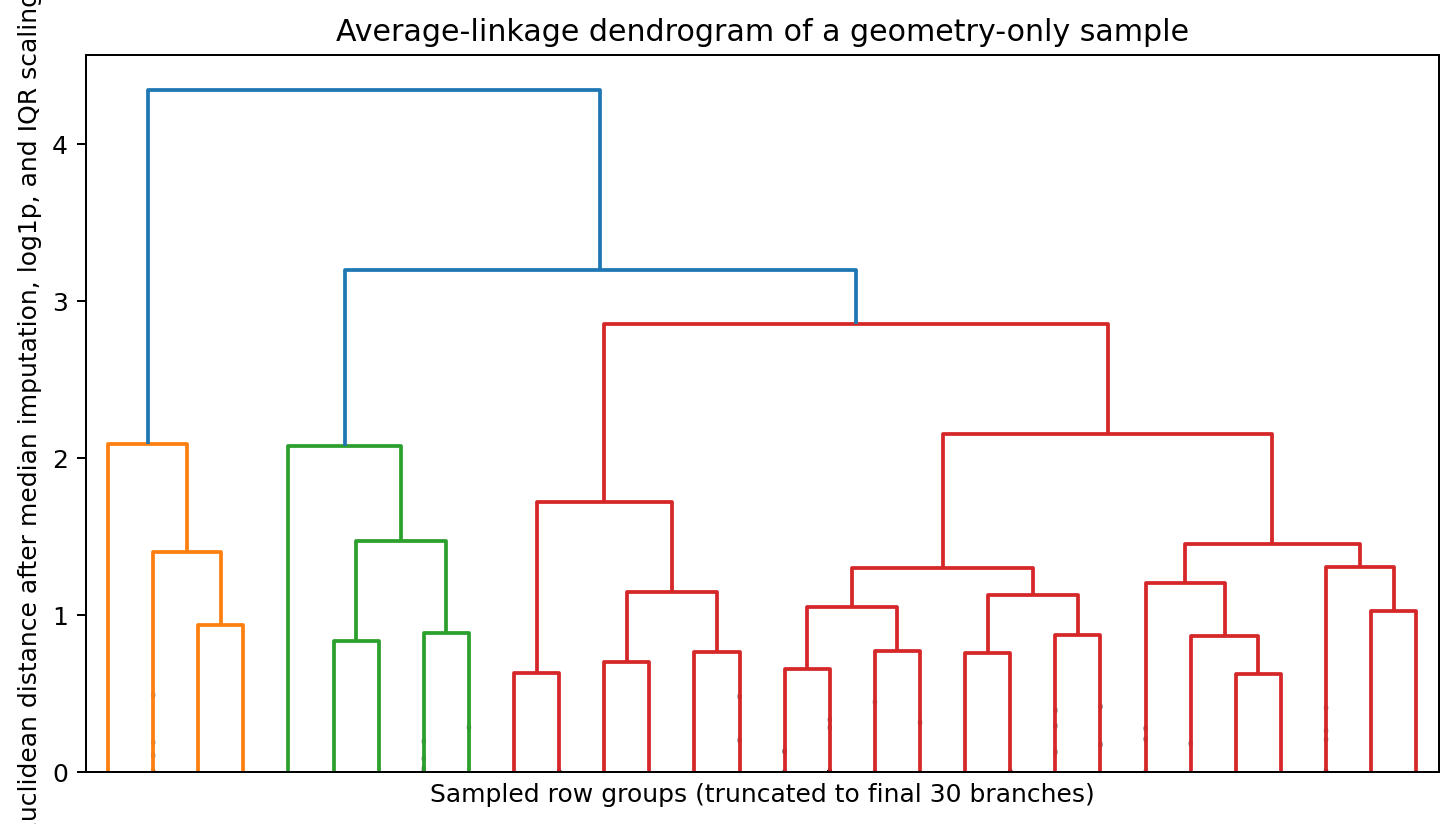

In [39]:
from IPython.display import Image, display
display(Image(filename=str(WORK_DIR / 'artifacts/report/figures/20_geometry_dendrogram_sample.png')))

## 13. Findings and limitations

- The source is imbalanced (about 86% nonad, 14% ad). On the original grouped holdout, the all-feature tree achieved ad recall 0.837 and ad F1 0.744. A separate training-only ANOVA top-100 sensitivity model reached ad F1 0.800 and precision 0.776 on the same holdout; feature selection was not cross-validated.
- Feature-only Apriori and CHARM reveal repeated URL/anchor-token combinations; class rules are generated separately and describe association, not causation.
- DBSCAN's selected unlabeled geometry setting found three clusters and marked 70 rows as noise. Its class alignment changes sharply with epsilon, so cluster/class agreement is not a stable finding.
- A data-derived `origurl → ancurl → url` pattern analysis used all rows, but its order is structural and analyst-defined, not temporal. The dataset still lacks timestamps, sessions, and event order. The synthetic GSP example is also only a demo; neither should be presented as observed user navigation.
- Fifteen-fold grouped CV supplements the holdout results. Both actual-data PySpark workloads and the synthetic repeated-row scale sweep are reported; Spark remained slower in the measured single-machine runs. The sweep has one timing per size and no model-quality estimate.

The project contains reusable scripts and generated artifacts. The LaTeX handoff is in `report_latex/`; the older ReportLab PDF and source ZIP predate the latest analyses and must not be treated as final.

## 14. Re-run instructions and sources

Run the relevant analysis commands from this directory (`bdHackathon/`) to regenerate the current artifacts and notebook:

```bash
python3 scripts/data_quality_audit.py
python3 scripts/preprocessing_model_sensitivity.py
python3 scripts/schema_role_sequential_mining.py
python3 scripts/grouped_cv_decision_tree.py
python3 build_notebook.py
```

The notebook reads the saved PySpark scale-sweep artifact rather than rerunning the resource-intensive Spark job on every notebook build. Its reproducible implementation is `scripts/scaled_tree_spark_benchmark.py`; the saved sweep completed in `local[2]` through 500,000 synthetic rows. Re-running Spark requires a functioning local Java gateway. The final report is being authored separately in `report_latex/`; the older ReportLab PDF and ZIP are stale and are not rebuilt here.

**Project source:** the assignment handout and course PDFs supplied the rubric and course forms. The dataset is [UCI Internet Advertisements](https://archive.ics.uci.edu/dataset/51/internet%2Badvertisements) ([download archive](https://archive.ics.uci.edu/static/public/51/internet+advertisements.zip)). Algorithm reference: [CHARM, Zaki & Hsiao (2002)](https://doi.org/10.1137/1.9781611972726.27). Tracking reference: [MLflow Tracking](https://mlflow.org/docs/latest/tracking/).